<a href="https://colab.research.google.com/github/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/capless_ldo_por_rf_harvest_sky130/capless_ldo_por_rf_harvest_sky130.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ISSCC 2027 Code-a-Chip**
# A Sub-8 µA Capacitor-less LDO with Class-AB Current-Buffer Transient Enhancement and a ZTC-Biased Hysteretic Power-On-Reset for RF/NFC-Harvested IoT Sensor Tags in SKY130

```
SPDX-FileCopyrightText: 2026 Poggy Macello Gultom
SPDX-License-Identifier: Apache-2.0
```

| Name | Affiliation | IEEE Member | SSCS Member | Email |
|---|---|---|---|---|
| Poggy Macello Gultom | Institut Teknologi Bandung (ITB), Indonesia | No | No | gultompoggy@gmail.com |

*All numbers in this notebook come from the simulations executed below (SKY130 + ngspice, schematic level).*

**At a glance (worst case over 45 PVT corners, all from the saved outputs):** LDO quiescent current **7.54 µA** (incl. 5 µA bleeder) ·
0↔1 mA load step with 100 ns edges **266 mV** (spec ≤ 300 mV; the plain-Miller v1 needed 398 mV) · stable with 10–100 pF and no
external capacitor · POR release 1.89–2.19 V with ≥ 250 mV hysteresis at 0.85–1.54 µA · every transistor thick-oxide, max 3.6 V stress.

## Abstract

Battery-less sensor tags powered by an NFC/RF energy harvester run from a small storage capacitor whose
voltage (`VIN`) rises slowly while energy is collected and falls quickly when the digital core wakes up.
They need two analog blocks: a regulator that turns this unregulated 1.8–3.3 V node into a clean 1.2 V rail with almost
no quiescent current and **without an external capacitor**, and a **power-on-reset (POR)** that releases the core only
after enough energy is stored. The POR must use **hysteresis**, otherwise the system gets stuck in a reset/brown-out loop.

This notebook designs both blocks at transistor level in the open-source **SkyWater SKY130** PDK and verifies them with
**ngspice**. It is fully scripted (netlists generated from Python), so the whole flow re-runs with "Run all":

* **Capacitor-less LDO**: a 2-stage loop with a weak-inversion 5T error amplifier, adaptive tail biasing, a small direct
  Miller capacitor and a **class-AB common-gate current-buffer coupling path** (Ahuja-type) from VOUT to the pass gate.
  During a fast load step, the buffers move the pass-gate charge through small-capacitance nodes, so the gate can swing *further* than
  the output (coupling gain > 1). A passive Miller capacitor cannot do this, because a capacitive divider has a gain of at most 1. The same buffers stabilize the loop
  (no right-half-plane zero) and carry a supply feed-forward path that improves mid-band PSRR. The result is **≈ 7.4 µA**
  quiescent current (including a 5 µA minimum-load bleeder), 0–1 mA load, and stability with 10–100 pF on-chip load capacitance over all
  corners/temperatures/supplies. All devices are **5 V thick-oxide (`g5v0d10v5`)** because every transistor sees the 3.3 V harvester node.
* **Design iteration, documented:** the first version of this LDO (plain Miller compensation, kept as `P_V1`) missed the
  100 ns load-step spec (≈ 400 mV droop at 125 °C) and had ≈ 0 dB PSRR around 100 kHz–1 MHz. Section 9.4 explains why passive
  Miller coupling cannot fix this. The notebook then shows before/after results for every affected spec.
* **ZTC-biased hysteretic POR**: a resistor divider plus a single NMOS threshold detector. The detector is biased at its
  **zero-temperature-coefficient (ZTC)** current density, so the release threshold stays flat over −40…125 °C without
  any reference. Total current is ≈ 0.85–1.55 µA.
* **System-level co-design**: a weak-inversion error amplifier has a fixed slew-rate-to-bandwidth ratio. We use this to
  derive the **minimum storage capacitance for a given harvester current**, then show intermittent (burst-mode) operation
  of a 1 mA tag core powered by a 300 µA harvester.

Every block is checked with DC, AC loop-gain, PSRR, transient, start-up, **PVT corners** (5 process corners × 3 temperatures × 3 supplies) and **Monte Carlo** mismatch.
The specs-vs-results table at the end lists PASS/FAIL with v1 (before) and v2 (after) columns. Every spec passes in v2,
some with thin margins, and the regressions v2 introduces are listed directly under the table.

## Table of Contents
1. [How to run](#run)
2. [Motivation and specifications](#spec)
3. [Tool installation](#install)
4. [Simulation helpers](#helpers)
5. [SKY130 thick-oxide device characterization (gm/Id + ZTC)](#char)
6. [Architecture](#arch)
7. [Hand analysis and sizing](#hand)
8. [Netlists](#netlist)
9. [Verification: DC, loop gain, PSRR, transients](#verif)
10. [Power-on-reset and system start-up](#por)
11. [PVT corners and Monte Carlo](#pvt)
12. [Device voltage-stress check](#stress)
13. [Specifications vs. results](#results)
14. [Limitations and future work](#limits)
15. [Reproducibility, tools & assistance, references](#refs)

<a name="run"></a>
## 1. How to run

**Google Colab (recommended):** click the badge at the top, then *Runtime → Run all*. The first cell installs
`ngspice` (conda-forge, via `micromamba`) and the SKY130 PDK (via `ciel`) into the Colab VM (≈ 3–5 min).
The ≈ 1,400 ngspice runs then took 5 min on 16 desktop CPU cores (WSL2). Scaling from an earlier 2-core measurement gives
≈ 14 min on 2 desktop cores, so expect roughly 20–35 min on the free Colab VM. Nothing is built from source.

**Linux / WSL2:** if `ngspice` is already on `PATH` and `$PDK_ROOT/sky130A` exists, the install cell is skipped.
Otherwise the same cell installs everything into the notebook folder (needs `curl`, `tar`, `bzip2`, `pip`).

Tested with: ngspice-41 (conda-forge), open_pdks sky130A `792ef67037d74c8c51811eab3ce23cf793491296` (via ciel 3.2.0),
Python 3.12, numpy, pandas, matplotlib, schemdraw 0.23. Simulation files go to `./sim_work/` (safe to delete).

<a name="spec"></a>
## 2. Motivation and specifications

### 2.1 The application
An NFC/RF-powered sensor tag (e.g. a temperature or humidity logger read by a phone) has no battery. The rectifier
charges a storage capacitor `C_st`; a shunt clamp limits it to ≈ 3.3 V. A 1.2 V digital core (MCU + sensor interface,
built with 1.8 V core devices) draws ≈ 1 mA while active and ≈ 0 while held in reset.

```
 antenna ─► rectifier ─► VIN (C_st, clamp 3.3 V) ─┬─► [cap-less LDO] ─► VOUT = 1.2 V ─► tag core (0 … 1 mA)
                                                   └─► [hysteretic POR] ─► RST_N ───────┘
```

Why these choices:
* **Quiescent current is the energy tax.** At the edge of the reading range the harvester delivers only tens to hundreds of µA.
  An LDO with 50 µA ground current would waste a large share of that, so we target ≤ 10 µA.
* **No external capacitor.** A µF output capacitor needs a pin and an SMD part, which a tag inlay does not have.
  The only output capacitance is the on-chip decoupling of the core (10–100 pF), so the loop must be stable with it.
* **Thick-oxide devices everywhere.** Every LDO and POR transistor sees the full `VIN` (up to 3.3 V, 3.6 V during clamp
  overshoot). SKY130 1.8 V devices (`*_01v8`) must not see more than 1.8 V (+10 %). We therefore use
  `sky130_fd_pr__{n,p}fet_g5v0d10v5` (5 V gate oxide, 10.5 V drain) for every transistor. Section 12 checks this automatically.
* **POR hysteresis.** When the core wakes up, `VIN` drops at (I_load − I_harv)/C_st. If the POR released and re-asserted
  at the same voltage, the system would oscillate around that point and never do useful work. The hysteresis window is
  the energy budget of one active burst: E = ½·C_st·(V_on² − V_off²).

### 2.2 Target specifications

In [1]:
import pandas as pd
SPEC = pd.DataFrame([
 ("VIN operating range",              "1.8 – 3.3 V",              "harvester storage node, clamped at 3.3 V"),
 ("VOUT",                             "1.2 V ± 3 % (PVT + 3σ MC)", "1.2 V digital core"),
 ("Load current",                     "0 – 1 mA",                 "MCU + sensor active current"),
 ("Quiescent current (LDO, no load)", "≤ 10 µA",                  "≤ ~5 % of a 200 µA harvester budget"),
 ("POR supply current",               "≤ 2 µA",                   "always-on block"),
 ("Dropout @ 1 mA (tt, 27 °C)",       "≤ 400 mV",                 "VIN,min − VOUT = 600 mV leaves margin"),
 ("Line regulation (DC)",             "≤ 5 mV/V",                 ""),
 ("Load regulation (DC)",             "≤ 5 mV/mA",                ""),
 ("Phase margin",                     "≥ 45 ° (0–1 mA, CL 10–100 pF, PVT)", "no external capacitor"),
 ("PSRR @ 1 kHz",                     "≥ 30 dB (all loads)",      "slow harvester ripple"),
 ("Load step 0↔1 mA, 100 ns edges",   "ΔVOUT ≤ 300 mV",           "core must stay above ≈ 0.9 V"),
 ("Load step 0↔1 mA, 1 µs edges",     "ΔVOUT ≤ 300 mV",           "core with soft clock start"),
 ("Line step 2↔3 V in 10 µs @0.5 mA", "ΔVOUT ≤ 100 mV",           "storage-cap slew"),
 ("POR rising threshold V_on",        "2.0 V ± 10 % (PVT)",       "energy stored before release"),
 ("POR hysteresis V_on − V_off",      "≥ 150 mV (PVT)",           "avoid brown-out oscillation"),
 ("POR falling threshold V_off",      "≥ 1.6 V (PVT)",            "LDO still in regulation when the core is released"),
], columns=["Parameter", "Target", "Reason"])
SPEC

,Parameter,Target,Reason
0,VIN operating range,1.8 – 3.3 V,"harvester storage node, clamped at 3.3 V"
1,VOUT,1.2 V ± 3 % (PVT + 3σ MC),1.2 V digital core
2,Load current,0 – 1 mA,MCU + sensor active current
3,"Quiescent current (LDO, no load)",≤ 10 µA,≤ ~5 % of a 200 µA harvester budget
4,POR supply current,≤ 2 µA,always-on block
5,"Dropout @ 1 mA (tt, 27 °C)",≤ 400 mV,"VIN,min − VOUT = 600 mV leaves margin"
6,Line regulation (DC),≤ 5 mV/V,
7,Load regulation (DC),≤ 5 mV/mA,
8,Phase margin,"≥ 45 ° (0–1 mA, CL 10–100 pF, PVT)",no external capacitor
9,PSRR @ 1 kHz,≥ 30 dB (all loads),slow harvester ripple


<a name="install"></a>
## 3. Tool installation

Following the Code-a-Chip FAQ recommendation, tools come from pre-built packages and nothing is compiled:
* `ngspice` from **conda-forge** via `micromamba` (pinned to version 41),
* the **SKY130 PDK** (open_pdks build, pinned commit) via **ciel**, the maintained successor of `volare`,
* `schemdraw` for the schematic drawings.

In [2]:
import os, shutil, subprocess, sys
PDK_HASH = "792ef67037d74c8c51811eab3ce23cf793491296"   # open_pdks sky130 build used for this notebook

def sh(cmd):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-2000:], r.stderr[-2000:]); raise RuntimeError(cmd)
    return r.stdout

if shutil.which("ngspice") is None:
    if not os.path.exists("conda-env/bin/ngspice"):
        sh("curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xvj bin/micromamba")
        sh("bin/micromamba create -y -q -r ./mamba -p ./conda-env -c conda-forge ngspice=41")
    os.environ["PATH"] = os.path.abspath("conda-env/bin") + os.pathsep + os.environ["PATH"]

os.environ.setdefault("PDK_ROOT", os.path.abspath("pdk"))
if not os.path.isdir(os.path.join(os.environ["PDK_ROOT"], "sky130A")):
    sh(f"{sys.executable} -m pip install -q ciel==3.2.0")
    sh(f"{sys.executable} -m ciel enable --pdk-root {os.environ['PDK_ROOT']} --pdk-family sky130 {PDK_HASH}")

try:
    import schemdraw
except ImportError:
    sh(f"{sys.executable} -m pip install -q schemdraw")

print(subprocess.run(["ngspice", "-v"], capture_output=True, text=True).stdout.splitlines()[1])
print("PDK_ROOT =", os.environ["PDK_ROOT"])

** ngspice-41 : Circuit level simulation program
PDK_ROOT = /home/poggy/cac/pdk


<a name="helpers"></a>
## 4. Simulation helpers

Each simulation is a netlist string generated in Python, run with `ngspice -b`. Results come back through `wrdata`
files and `meas`/`print` statements. Two practical details:

* **Fast model loading.** `.lib sky130.lib.spice tt` parses models for every SKY130 device (~10 s per run).
  `models()` writes a small library that includes exactly the same corner files, but only for the devices used here
  (`g5v0d10v5` FETs, `xhigh_po` resistors, MIM capacitors). Each run then takes < 0.1 s, which makes PVT and Monte Carlo cheap.
* **Monte Carlo.** SKY130 mismatch is enabled with `mc_mm_switch=1` (the `*_mm` libraries). Each Monte Carlo sample is a separate
  ngspice run with its own `.option seed`, so every sample can be reproduced exactly.

In [3]:
import os, re, subprocess, shutil, hashlib, itertools, concurrent.futures as _futures
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11, "font.size": 9})

# ---------------------------------------------------------------- ngspice runner
PDK_ROOT = os.environ["PDK_ROOT"]
NGS = f"{PDK_ROOT}/sky130A/libs.tech/ngspice"
REF = f"{PDK_ROOT}/sky130A/libs.ref/sky130_fd_pr/spice"
SIMDIR = os.path.abspath("sim_work")
os.makedirs(SIMDIR, exist_ok=True)
with open(os.path.join(SIMDIR, ".spiceinit"), "w") as f:     # same settings as the PDK's spinit
    f.write("set ngbehavior=hsa\nset skywaterpdk\nset ng_nomodcheck\nset num_threads=1\n"
            "option noinit\noption klu\nset wr_singlescale\nset wr_vecnames\n")
_meas = re.compile(r"^\s*([A-Za-z_][^\s=]*)\s*=\s*([-+]?[0-9.]+(?:[eE][-+]?\d+)?)(?=\s|$)", re.M)

def spice(net, tag, timeout=900):
    """Write a netlist, run `ngspice -b`, return {name: value} of every printed/measured scalar."""
    path = os.path.join(SIMDIR, f"{tag}.spice")
    with open(path, "w") as f:
        f.write(net)
    r = subprocess.run(["ngspice", "-b", path], cwd=SIMDIR, capture_output=True, text=True, timeout=timeout)
    out = r.stdout + r.stderr
    with open(os.path.join(SIMDIR, f"{tag}.log"), "w") as f:
        f.write(out)
    if r.returncode != 0 or "fatal" in out.lower():
        raise RuntimeError(f"ngspice failed for {tag}:\n" + out[-3000:])
    return {k.lower(): float(v) for k, v in _meas.findall(out)}

def wrdata(tag):
    return pd.read_csv(os.path.join(SIMDIR, f"{tag}.dat"), sep=r"\s+")

def pmap(fn, items, workers=None):
    """Run independent simulations in parallel (each is its own ngspice process)."""
    with _futures.ThreadPoolExecutor(workers or max(2, os.cpu_count() or 2)) as ex:
        return list(ex.map(fn, items))

def models(corner="tt", mc=False):
    """Light-weight equivalent of `.lib sky130.lib.spice <corner>[_mm]` for the devices used here."""
    fn = os.path.join(SIMDIR, f"models_{corner}{'_mm' if mc else ''}.lib")
    if not os.path.exists(fn):
        with open(fn, "w") as f:
            f.write(f"* subset of sky130.lib.spice, corner {corner}\n"
                    f".param mc_mm_switch={1 if mc else 0}\n.param mc_pr_switch=0\n"
                    f".include \"{NGS}/corners/{corner}/nonfet.spice\"\n")
            for d in ("nfet_g5v0d10v5", "pfet_g5v0d10v5"):
                f.write(f".include \"{REF}/sky130_fd_pr__{d}__{corner}.corner.spice\"\n"
                        f".include \"{REF}/sky130_fd_pr__{d}__mismatch.corner.spice\"\n")
            f.write(f".include \"{NGS}/all.spice\"\n"
                    f".include \"{NGS}/r+c/res_typical__cap_typical.spice\"\n"
                    f".include \"{NGS}/r+c/res_typical__cap_typical__lin.spice\"\n")
    return f".include \"{fn}\"\n"

def char(kind, L, temp=27, corner="tt", vds=1.0, W=5):
    """DC sweep of one thick-oxide FET: returns |VGS|, |Id|, gm (numerical derivative)."""
    tag = f"char_{kind}_{W}_{L}_{temp}_{corner}".replace(".", "p").replace("-", "m")
    m = f"sky130_fd_pr__{kind}fet_g5v0d10v5"
    sgn = 1 if kind == "n" else -1
    net = (f"* char\n{models(corner)}.temp {temp}\nXM1 d g 0 0 {m} W={W} L={L} nf=1\n"
           f"Vd d 0 {sgn*vds}\nVg g 0 0\n.control\ndc Vg 0 {sgn*2.5} {sgn*0.005}\n"
           f"let id=abs(i(Vd))\nwrdata {tag}.dat id\n.endc\n.end\n")
    spice(net, tag); d = wrdata(tag)
    v = np.abs(d.iloc[:, 0].values); i = d["id"].values
    return v, i, np.gradient(i, v)

# ---------------------------------------------------------------- circuit generators
def fet(name, d, g, s, b, kind, W, L, nf=1, m=1):
    """sky130 thick-oxide (g5v0d10v5) FET instance with xschem-style diffusion geometry."""
    wf = W / nf
    ad = int((nf + 1) / 2) * wf * 0.29; as_ = int((nf + 2) / 2) * wf * 0.29
    pd_ = 2 * int((nf + 1) / 2) * (wf + 0.29); ps = 2 * int((nf + 2) / 2) * (wf + 0.29)
    return (f"X{name} {d} {g} {s} {b} sky130_fd_pr__{kind}fet_g5v0d10v5 W={W} L={L} nf={nf} "
            f"ad={ad:.4g} as={as_:.4g} pd={pd_:.4g} ps={ps:.4g} nrd={0.29/W:.4g} nrs={0.29/W:.4g} "
            f"sa=0 sb=0 sd=0 mult={m} m={m}\n")

def res(name, a, b, R):
    """xhigh_po poly resistor, W = 0.35 um (~2 kohm/sq); length computed from the target value."""
    L = R / 2000 * (0.35 - 0.056) + 0.0592
    return f"X{name} {a} {b} 0 sky130_fd_pr__res_xhigh_po_0p35 L={L:.4g} mult=1\n"

P0 = dict(
    Ib=250e-9,                  # reference current (ideal; from a nano-power reference in a full chip)
    Win=8, Lin=2,               # NMOS input pair (weak inversion)
    Wld=16, Lld=4,              # PMOS mirror load (v1: 4/4; wider in v2 for headroom at VIN = 1.8 V with the 1 uA tail)
    Wb=2, Lb=4,                 # bias diode / unit current-source device
    mt=4,                       # tail = 4 x Ib = 1 uA (v1: 0.5 uA)
    mbl=20,                     # bleeder = 20 x Ib = 5 uA (minimum load)
    Wp=400, Lp=0.5, nfp=40,     # pass PMOS
    Ws=0.84, Ls=0.5,            # adaptive-bias sense PMOS (1/476 of pass)
    Wa=1, La=4, ma=1,           # adaptive-bias NMOS mirror
    Cc_side=30, Cc_mf=1,        # direct Miller cap, 30 x 30 um MIM (~1.8 pF)
    # --- v2: class-AB common-gate current-buffer coupling (transient enhancement + Ahuja-type compensation)
    mx=3,                       # buffer bias Ix = mx * Ib = 0.75 uA (one stack VIN -> MPT -> MPX -> vg -> MNX -> MNS -> GND)
    Cf_side=55,                 # Cfp = Cfn = 55 x 55 um MIM (~6 pF each), VOUT -> buffer sources
    Wpb=4, Lpb=4,               # PMOS bias diode MPB2 / current source MPT / buffer MPX (unit; long L for output resistance)
    Wnx=4, Lnx=1,               # NMOS buffer MNX (unit), gate at VREF
    Rsh=1.4e6,                  # level shift: vbp = VIN - VSG - Ib*Rsh  -> tx ~ VIN - 0.35 V
    Cff_side=32,                # supply feed-forward VIN -> sx (~2 pF): injects C*dVIN/dt into vg (PSRR)
    Cbp_side=22,                # vbp filter cap (~1 pF): PMOS-buffer bias does not follow fast VIN ripple
    R1=1.9e6, R2=3.2e6, R3=1.28e6, Rpu=4e6,    # POR divider / pull-up
    Wd=0.7, Ld=20,              # POR detector (near-ZTC current density)
    Winv=0.42, Linv=4,          # POR inverters
)
# the first version of this design (before the transient-enhancement update), kept for before/after comparisons
P_V1 = dict(P0, mt=2, Wld=4, mbl=30, Cc_side=70, mx=0, Cff_side=0, Cbp_side=0)

def ldo_subckt(p):
    s = ".subckt ldo vin vout fb vref gnd\n"
    s += f"Bref vin nb I={p['Ib']}*(1-exp(-max(V(vin)-V(nb),0)/0.05))\n"   # ideal Iref with compliance
    s += fet("MNB", "nb", "nb", "gnd", "gnd", "n", p['Wb'], p['Lb'])
    s += fet("MN5", "tail", "nb", "gnd", "gnd", "n", p['Wb'], p['Lb'], m=p['mt'])
    s += fet("MN1", "n1", "fb", "tail", "gnd", "n", p['Win'], p['Lin'])
    s += fet("MN2", "vg", "vref", "tail", "gnd", "n", p['Win'], p['Lin'])
    s += fet("MP3", "n1", "n1", "vin", "vin", "p", p['Wld'], p['Lld'])
    s += fet("MP4", "vg", "n1", "vin", "vin", "p", p['Wld'], p['Lld'])
    s += fet("MPP", "vout", "vg", "vin", "vin", "p", p['Wp'], p['Lp'], nf=p['nfp'])
    s += fet("MPS", "na", "vg", "vin", "vin", "p", p['Ws'], p['Ls'])
    s += fet("MNA", "na", "na", "gnd", "gnd", "n", p['Wa'], p['La'])
    s += fet("MNA2", "tail", "na", "gnd", "gnd", "n", p['Wa'], p['La'], m=p['ma'])
    s += fet("MNBL", "vout", "nb", "gnd", "gnd", "n", p['Wb'], p['Lb'], m=p['mbl'])
    s += f"XCc vg vout sky130_fd_pr__cap_mim_m3_1 W={p['Cc_side']} L={p['Cc_side']} MF={p['Cc_mf']}\n"
    if p.get('mx', 0) > 0:
        # bias for the PMOS buffer gate: diode MPB2 (Ib) + level-shift resistor Rsh -> vbp, sink MNB3 (Ib)
        s += fet("MPB2", "pa", "pa", "vin", "vin", "p", p['Wpb'], p['Lpb'])
        s += f"XRsh pa vbp gnd sky130_fd_pr__res_xhigh_po_0p35 L={p['Rsh']/2000*(0.35-0.056)+0.0592:.4g} mult=1\n"
        s += fet("MNB3", "vbp", "nb", "gnd", "gnd", "n", p['Wb'], p['Lb'])
        # class-AB current-buffer stack (static current Ix cancels at vg)
        s += fet("MPT", "tx", "pa", "vin", "vin", "p", p['Wpb'], p['Lpb'], m=p['mx'])
        s += fet("MPX", "vg", "vbp", "tx", "vin", "p", p['Wpb'], p['Lpb'], m=p['mx'])
        s += fet("MNX", "vg", "vref", "sx", "gnd", "n", p['Wnx'], p['Lnx'], m=p['mx'])
        s += fet("MNS", "sx", "nb", "gnd", "gnd", "n", p['Wb'], p['Lb'], m=p['mx'])
        s += f"XCfp vout tx sky130_fd_pr__cap_mim_m3_1 W={p['Cf_side']} L={p['Cf_side']} MF=1\n"
        s += f"XCfn vout sx sky130_fd_pr__cap_mim_m3_1 W={p['Cf_side']} L={p['Cf_side']} MF=1\n"
        if p.get('Cff_side', 0) > 0:
            s += f"XCff vin sx sky130_fd_pr__cap_mim_m3_1 W={p['Cff_side']} L={p['Cff_side']} MF=1\n"
        if p.get('Cbp_side', 0) > 0:
            s += f"XCbp vbp gnd sky130_fd_pr__cap_mim_m3_1 W={p['Cbp_side']} L={p['Cbp_side']} MF=1\n"
    return s + ".ends ldo\n"

def mim_area(p):
    """total MIM area of the LDO in um^2"""
    a = p['Cc_side']**2 * p['Cc_mf']
    if p.get('mx', 0) > 0:
        a += 2 * p['Cf_side']**2 + p.get('Cff_side', 0)**2 + p.get('Cbp_side', 0)**2
    return a

def por_subckt(p):
    s = ".subckt por vin vout rstn pg gnd\n"
    s += res("R1", "vin", "div", p['R1']) + res("R2", "div", "dm", p['R2']) + res("R3", "dm", "gnd", p['R3'])
    s += fet("MH", "dm", "pgb", "gnd", "gnd", "n", 1, 0.5)                 # hysteresis switch
    s += res("Rpu", "vin", "x", p['Rpu'])
    s += fet("MD", "x", "div", "gnd", "gnd", "n", p['Wd'], p['Ld'])         # threshold detector
    s += fet("MI1P", "pg", "x", "vin", "vin", "p", 2*p['Winv'], p['Linv'])  # INV1 (long L: low crowbar)
    s += fet("MI1N", "pg", "x", "gnd", "gnd", "n", p['Winv'], p['Linv'])
    s += fet("MI2P", "pgb", "pg", "vin", "vin", "p", 2*p['Winv'], 0.5)      # INV2
    s += fet("MI2N", "pgb", "pg", "gnd", "gnd", "n", p['Winv'], 0.5)
    s += fet("MI3P", "rstn", "pgb", "vout", "vout", "p", 2*p['Winv'], 0.5)  # INV3, VOUT domain
    s += fet("MI3N", "rstn", "pgb", "gnd", "gnd", "n", p['Winv'], 0.5)
    return s + ".ends por\n"

VREF_SRC = "Bvref vref 0 V=1.2/(1+exp(-(V(vin)-1.4)/0.04))\n"   # ideal 1.2 V reference, valid above ~1.5 V

def tb(P, body, control, corner="tt", temp=27, mc=False, seed=None, por=False):
    s = "* testbench\n" + (f".option seed={seed}\n" if seed is not None else "")
    s += models(corner, mc) + f".temp {temp}\n.option gmin=1e-15 reltol=1e-4\n"
    s += ldo_subckt(P) + (por_subckt(P) if por else "") + VREF_SRC + body
    return s + ".control\n" + control + "\n.endc\n.end\n"

# ---------------------------------------------------------------- analyses
def _t(P, *a):
    h = hashlib.md5(repr(sorted(P.items())).encode()).hexdigest()[:6]
    return (h + "_" + "_".join(str(x) for x in a)).replace("-", "m").replace(".", "p")

def op_point(P, vin=2.5, il=0.0, corner="tt", temp=27, mc=False, seed=None):
    tag = _t(P, "op", vin, il, corner, temp, seed)
    body = f"Vin vin 0 {vin}\nXldo vin vout vout vref 0 ldo\nCL vout 0 100p\nIl vout 0 {il}\n"
    ctl = "op\nlet iq=-i(Vin)-%g\nlet vout=v(vout)\nlet vg=v(xldo.vg)\nprint vout vg iq" % il
    r = spice(tb(P, body, ctl, corner, temp, mc, seed), tag)
    return dict(vout=r["vout"], vg=r["vg"], iq=r["iq"])

def dc_line(P, il=0.0, corner="tt", temp=27):
    """VIN sweep 1.2 -> 3.6 V with a resistive load drawing `il` at 1.2 V (well-defined in dropout)."""
    tag = _t(P, "line", il, corner, temp)
    rl = f"Rl vout 0 {1.2/il:.6g}\n" if il > 0 else ""
    body = f"Vin vin 0 2.5\nXldo vin vout vout vref 0 ldo\n{rl}"
    iload = f"-v(vout)/{1.2/il:.6g}" if il > 0 else ""
    ctl = f"dc Vin 1.2 3.6 0.005\nlet iq=-i(Vin){iload}\nwrdata {tag}.dat v(vout) iq"
    spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); d.columns = ["vin", "vout", "iq"]; return d

def dc_load(P, vin=2.5, corner="tt", temp=27, i1=1.5e-3):
    tag = _t(P, "load", vin, corner, temp)
    body = f"Vin vin 0 {vin}\nXldo vin vout vout vref 0 ldo\nIl vout 0 0\n"
    ctl = f"dc Il 0 {i1} {i1/300}\nwrdata {tag}.dat v(vout)"
    spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); d.columns = ["il", "vout"]; return d

def _pm(f, mag, ph):
    ph = np.unwrap(np.deg2rad(ph)) * 180 / np.pi
    ph = ph - 360 * np.round(ph[0] / 360)
    k = np.where(mag < 0)[0]
    if len(k) == 0 or k[0] == 0:
        return np.nan, np.nan, ph
    k = k[0]; lf = np.log10(f)
    fu = 10 ** np.interp(0, [mag[k], mag[k - 1]], [lf[k], lf[k - 1]])
    return fu, 180 + np.interp(np.log10(fu), lf[k - 1:k + 1], ph[k - 1:k + 1]), ph

def loop(P, vin=2.5, il=0.0, cl=100e-12, corner="tt", temp=27):
    """Loop gain T = -v(vout)/v(fb), loop opened at the error-amplifier gate (capacitive node):
    DC kept by unity buffer + 1e9 s low-pass, AC injected in series."""
    tag = _t(P, "lg", vin, il, cl, corner, temp)
    body = (f"Vin vin 0 {vin}\nXldo vin vout fb vref 0 ldo\nCL vout 0 {cl}\nIl vout 0 {il}\n"
            "Ebuf vb 0 vout 0 1\nRlp vb fbdc 1G\nClp fbdc 0 1\nVinj fb fbdc dc 0 ac 1\n")
    ctl = f"ac dec 40 0.1 1G\nlet t=-v(vout)/v(fb)\nlet mag=db(t)\nlet ph=180/pi*cph(t)\nwrdata {tag}.dat mag ph"
    spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); f = d.iloc[:, 0].values; mag = d["mag"].values
    fu, pm, ph = _pm(f, mag, d["ph"].values)
    return dict(f=f, mag=mag, ph=ph, a0=mag[0], fu=fu, pm=pm)

def psrr(P, vin=2.5, il=0.0, cl=100e-12, corner="tt", temp=27):
    tag = _t(P, "psrr", vin, il, cl, corner, temp)
    body = f"Vin vin 0 dc {vin} ac 1\nXldo vin vout vout vref 0 ldo\nCL vout 0 {cl}\nIl vout 0 {il}\n"
    ctl = f"ac dec 20 1 100Meg\nlet psrr=-db(v(vout))\nwrdata {tag}.dat psrr"
    spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); d.columns = ["f", "psrr"]; return d

def tran_load(P, vin=2.5, ilo=0.0, ihi=1e-3, tr=100e-9, cl=100e-12, corner="tt", temp=27,
              t1=20e-6, t2=60e-6, tstop=100e-6):
    tag = _t(P, "tload", vin, ilo, ihi, tr, cl, corner, temp)
    body = (f"Vin vin 0 {vin}\nXldo vin vout vout vref 0 ldo\nCL vout 0 {cl}\n"
            f"Il vout 0 PWL(0 {ilo} {t1} {ilo} {t1+tr} {ihi} {t2} {ihi} {t2+tr} {ilo})\n")
    ctl = (f"tran 5n {tstop} 0 20n\nmeas tran vmin min v(vout) from={t1} to={t2}\n"
           f"meas tran vmax max v(vout) from={t2} to={tstop}\nmeas tran vpre avg v(vout) from={t1-5e-6} to={t1}\n"
           f"linearize v(vout)\nwrdata {tag}.dat v(vout)")
    r = spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); d.columns = ["t", "vout"]; return d, r

def tran_line(P, v0=2.0, v1=3.0, tr=1e-6, il=0.5e-3, cl=100e-12, corner="tt", temp=27,
              t1=20e-6, t2=60e-6, tstop=100e-6):
    tag = _t(P, "tline", v0, v1, tr, il, cl, corner, temp)
    body = (f"Vin vin 0 PWL(0 {v0} {t1} {v0} {t1+tr} {v1} {t2} {v1} {t2+tr} {v0})\n"
            f"Xldo vin vout vout vref 0 ldo\nCL vout 0 {cl}\nIl vout 0 {il}\n")
    ctl = (f"tran 5n {tstop} 0 20n\nmeas tran vmax max v(vout) from={t1} to={t2}\n"
           f"meas tran vmin min v(vout) from={t2} to={tstop}\nmeas tran vpre avg v(vout) from={t1-5e-6} to={t1}\n"
           f"linearize v(vin) v(vout)\nwrdata {tag}.dat v(vin) v(vout)")
    r = spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); d.columns = ["t", "vin", "vout"]; return d, r

def por_sweep(P, corner="tt", temp=27, mc=False, seed=None, vpk=3.3, tramp=2e-3):
    """Slow triangular VIN ramp 0 -> vpk -> 0. V_on / V_off = VIN where RST_N toggles."""
    tag = _t(P, "por", corner, temp, seed, tramp)
    body = (f"Vin vin 0 PWL(0 0 {tramp} {vpk} {2*tramp} 0)\nXldo vin vout vout vref 0 ldo\nCL vout 0 100p\n"
            "Vam vin vinp 0\nXpor vinp vout rstn pg 0 por\nCrst rstn 0 50f\n")
    ctl = (f"tran {tramp/4000:.4g} {2*tramp} 0 {tramp/4000:.4g}\nlet iin=i(Vam)\n"
           f"linearize v(vin) v(vout) v(pg) v(rstn) iin\nwrdata {tag}.dat v(vin) v(vout) v(pg) v(rstn) iin")
    r = spice(tb(P, body, ctl, corner, temp, mc, seed, por=True), tag)
    d = wrdata(tag); d.columns = ["t", "vin", "vout", "pg", "rstn", "iin"]
    up = (d.t < tramp) & (d.vin > 1.2); dn = d.t > tramp
    good = d.rstn > np.maximum(0.5 * d.vout, 0.3)      # RST_N high (and not just numerical noise near 0 V)
    k1 = np.where(up & good)[0]; k2 = np.where(dn & ~good)[0]
    r["von"] = d.vin[k1[0]] if len(k1) else np.nan
    r["voff"] = d.vin[k2[0]] if len(k2) else np.nan
    return d, r

def system_startup(P, iharv=300e-6, cst=47e-9, iload=1e-3, corner="tt", temp=27, tstop=1.6e-3):
    """Harvester (current source) -> C_st with 3.3 V soft clamp -> LDO + POR -> 1 mA core enabled by RST_N
    (1 us RC on the enable models the clock start-up)."""
    tag = _t(P, "sys", iharv, cst, iload, corner, temp)
    body = (f"Ih 0 vin {iharv}\nCst vin 0 {cst}\nBclamp vin 0 I=1e-3*ln(1+exp((V(vin)-3.3)/0.02))\n"
            "Xldo vin vout vout vref 0 ldo\nCL vout 0 100p\nXpor vin vout rstn pg 0 por\n"
            "Ren rstn en 1Meg\nCen en 0 1p\n"
            f"Bcore vout 0 I={iload}*0.5*(1+tanh((V(en)-0.6)/0.03))*(1-exp(-max(V(vout),0)/0.1))\n"
            ".ic v(vin)=0 v(vout)=0\n")
    ctl = f"tran 20n {tstop} 0 50n uic\nlinearize v(vin) v(vout) v(rstn) v(en)\nwrdata {tag}.dat v(vin) v(vout) v(rstn) v(en)"
    r = spice(tb(P, body, ctl, corner, temp, por=True), tag)
    d = wrdata(tag); d.columns = ["t", "vin", "vout", "rstn", "en"]
    d["iload"] = iload * 0.5 * (1 + np.tanh((d.en - 0.6) / 0.03)) * (1 - np.exp(-np.maximum(d.vout, 0) / 0.1))
    return d, r

def stress_check(P, conditions=((3.6, 0.0), (3.6, 1e-3), (1.9, 0.0), (1.0, 0.0))):
    """Operating-point voltage stress on every FET of the LDO + POR."""
    sub = {"ldo": (ldo_subckt(P), {"vin": "vin", "vout": "vout", "fb": "vout", "vref": "vref", "gnd": "0"}),
           "por": (por_subckt(P), {"vin": "vin", "vout": "vout", "rstn": "rstn", "pg": "pg", "gnd": "0"})}
    rows = {}
    for vin, il in conditions:
        tag = _t(P, "stress", vin, il)
        body = (f"Vin vin 0 {vin}\nXldo vin vout vout vref 0 ldo\nCL vout 0 100p\nIl vout 0 {il}\n"
                "Xpor vin vout rstn pg 0 por\n")
        r = spice(tb(P, body, "op\nprint all", por=True), tag)
        V = lambda inst, net: 0.0 if sub[inst][1].get(net, net) == "0" else \
            r.get(sub[inst][1][net] if net in sub[inst][1] else f"x{inst}.{net}", np.nan)
        for inst, (txt, _) in sub.items():
            for line in txt.splitlines():
                if not line.startswith("XM"):
                    continue
                t = line.split(); dev, (d, g, s, b), model = t[0][1:], t[1:5], t[5]
                vd, vg, vs, vb = (V(inst, n) for n in (d, g, s, b))
                w = max(abs(vg - vs), abs(vd - vs), abs(vg - vd), abs(vg - vb))   # oxide + channel stress
                key = (inst, dev)
                if key not in rows or w > rows[key]["worst_V"]:
                    rows[key] = dict(block=inst, device=dev, model=model.replace("sky130_fd_pr__", ""),
                                     worst_V=w, at=f"VIN={vin} V, IL={il*1e3:g} mA",
                                     VGS=abs(vg - vs), VDS=abs(vd - vs))
    return pd.DataFrame(rows.values())

def small_step(P, il=0.0, di=None, cl=100e-12, vin=2.5, corner="tt", temp=27):
    """Small load step il -> il+di (100 ns edge). Returns waveform and overshoot of the recovery in % of the
    initial deviation (a second-order loop with PM 45/60/75 deg rings by roughly 25/10/2 %)."""
    di = di if di is not None else max(0.1 * il, 2e-6)
    tag = _t(P, "sstep", il, di, cl, vin, corner, temp)
    body = (f"Vin vin 0 {vin}\nXldo vin vout vout vref 0 ldo\nCL vout 0 {cl}\n"
            f"Il vout 0 PWL(0 {il} 20u {il} 20.1u {il+di})\n")
    ctl = f"tran 2n 60u 0 10n\nlinearize v(vout)\nwrdata {tag}.dat v(vout)"
    spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); d.columns = ["t", "vout"]
    v0 = d.vout[(d.t > 15e-6) & (d.t < 20e-6)].mean(); vf = d.vout[d.t > 55e-6].mean()
    a = d[d.t > 20e-6]; kmin = a.vout.idxmin(); dip = vf - a.vout[kmin]
    after = a[a.t > a.t[kmin]]; over = after.vout.max() - vf
    return d, dict(dip_mV=dip * 1e3, overshoot_pct=100 * over / dip if dip > 0 else np.nan)

def psrr_band(P, il=0.0, f1=1e5, f2=1e6, corner="tt", temp=27, vin=2.5):
    d = psrr(P, vin, il, corner=corner, temp=temp); m = (d.f >= f1) & (d.f <= f2)
    return d.psrr[m].min()

<a name="char"></a>
## 5. SKY130 thick-oxide device characterization

Before sizing anything we sweep the two devices we will use (`nfet_g5v0d10v5`, `pfet_g5v0d10v5`) and build
**gm/Id lookup tables** (Jespers & Murmann). Sizing then means choosing an inversion level (gm/Id) and a length, and reading the
current density Id/W from the table, instead of relying on the square law, which does not hold in weak and moderate inversion.

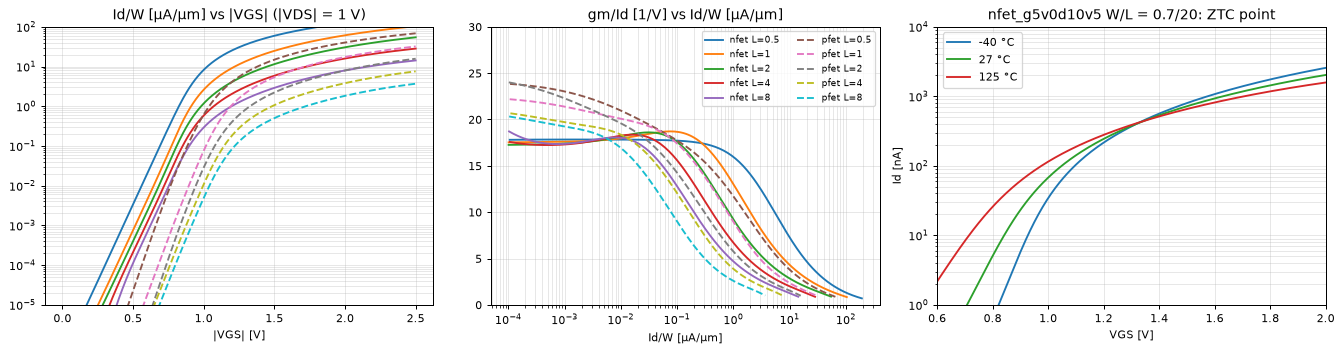

nfet_g5v0d10v5 L=1: |VGS| for 1 µA/µm = 0.91 V, for 10 nA/µm = 0.65 V
pfet_g5v0d10v5 L=1: |VGS| for 1 µA/µm = 1.19 V, for 10 nA/µm = 0.89 V


In [4]:
LS = [0.5, 1, 2, 4, 8]
LUT = {(k, L): char(k, L) for k in "np" for L in LS}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, ls in (("n", "-"), ("p", "--")):
    for L in LS:
        v, i, g = LUT[(k, L)]
        m = i > 1e-12 * 5
        ax[0].semilogy(v, i / 5 * 1e6, ls, label=f"{k}fet L={L}")
        ok = (i / 5 > 1e-6 * 1e-4)
        ax[1].semilogx(i[ok] / 5 * 1e6, (g / i)[ok], ls, label=f"{k}fet L={L}")
for a, t in zip(ax[:2], ["Id/W [µA/µm] vs |VGS| (|VDS| = 1 V)", "gm/Id [1/V] vs Id/W [µA/µm]"]):
    a.set_title(t); a.grid(True, which="both", alpha=.3)
ax[0].set_xlabel("|VGS| [V]"); ax[1].set_xlabel("Id/W [µA/µm]"); ax[1].set_ylim(0, 30); ax[0].set_ylim(1e-5, 1e2)
ax[1].legend(fontsize=7, ncol=2)
# ZTC: NMOS L = 20 um (POR detector length) at three temperatures
for T, c in zip((-40, 27, 125), ("tab:blue", "tab:green", "tab:red")):
    v, i, g = char("n", 20, temp=T, W=0.7)
    ax[2].semilogy(v, i * 1e9, color=c, label=f"{T} °C")
ax[2].set_title("nfet_g5v0d10v5 W/L = 0.7/20: ZTC point"); ax[2].set_xlabel("VGS [V]"); ax[2].set_ylabel("Id [nA]")
ax[2].set_xlim(0.6, 2.0); ax[2].set_ylim(1, 1e4); ax[2].grid(True, which="both", alpha=.3); ax[2].legend()
plt.tight_layout(); plt.show()

for k in "np":
    v, i, g = LUT[(k, 1)]
    print(f"{k}fet_g5v0d10v5 L=1: |VGS| for 1 µA/µm = {np.interp(1e-6*5, i, v):.2f} V, "
          f"for 10 nA/µm = {np.interp(1e-8*5, i, v):.2f} V")

**How to read these plots.**
*Left:* the PMOS thick-oxide device needs about 0.2–0.3 V more |VGS| than the NMOS for the same current density, and its
threshold is high (≈ 1.1–1.3 V). This matters at VIN = 1.8 V, where the pass transistor only has about 1.35 V of gate drive.
*Middle:* gm/Id reaches ≈ 18 V⁻¹ (NMOS) to ≈ 24 V⁻¹ (PMOS) in weak inversion (Id/W ≲ 0.05 µA/µm) and falls to ≈ 5 V⁻¹ in strong inversion.
*Right:* the three Id–VGS curves of a long NMOS cross near a single **zero-temperature-coefficient (ZTC)** point. Below it the
current rises with temperature (threshold voltage dominates); above it the current falls (mobility dominates). A
detector biased **at** the ZTC current trips at the same VGS at every temperature. The POR in Section 10 uses this.

<a name="arch"></a>
## 6. Architecture

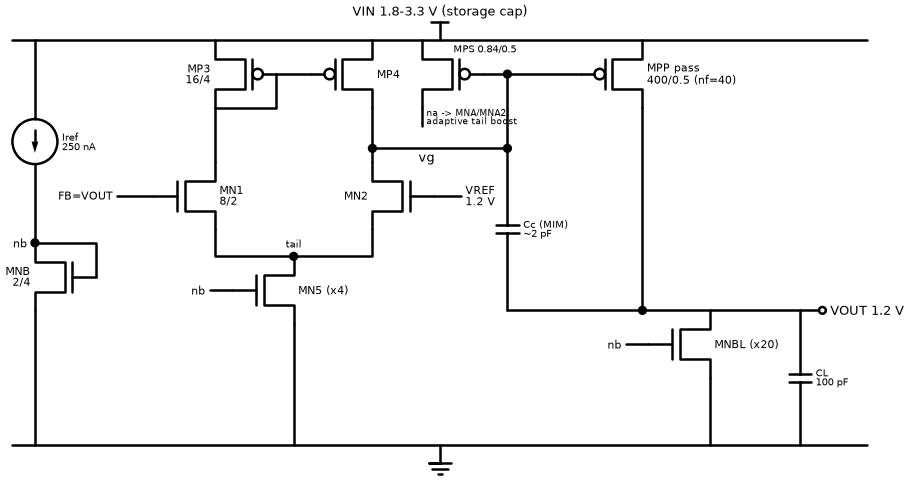

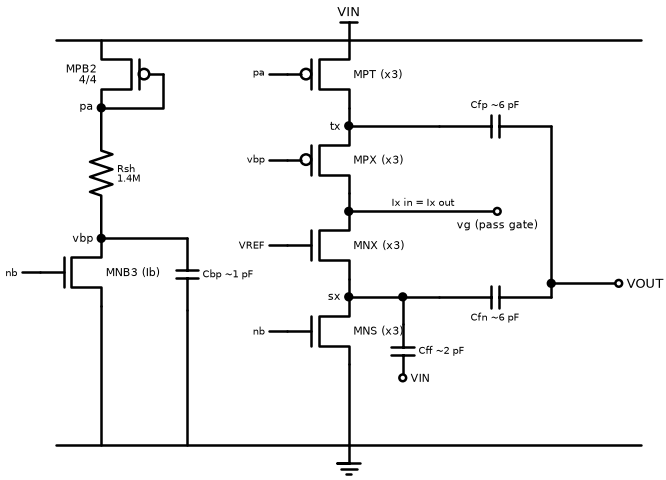

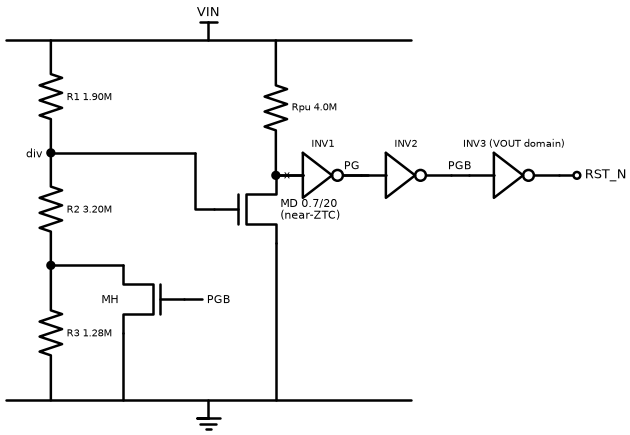

In [5]:
import schemdraw, schemdraw.elements as elm, schemdraw.logic as logic

def _fet(d, kind, src_or_drain_top, xy, gate_left=False, label=""):
    """Place a FET with its top terminal (PMOS source / NMOS drain) at xy."""
    e = (elm.PFet() if kind == "p" else elm.NFet()).right()
    if gate_left:
        e = e.reverse()
    e = e.anchor("source" if kind == "p" else "drain").at(xy)
    if label:
        e = e.label(label, loc="right" if gate_left else "left", fontsize=9)
    return d.add(e)

def draw_ldo(P, fname=None):
    with schemdraw.Drawing(show=False, fontsize=10) as d:
        d.config(unit=2)
        VIN, GND = 9.0, 0.0
        d.add(elm.Line().at((-1.5, VIN)).to((17.5, VIN)))
        d.add(elm.Vdd().at((8, VIN)).label("VIN 1.8-3.3 V (storage cap)"))
        d.add(elm.Line().at((-1.5, GND)).to((17.5, GND)))
        d.add(elm.Ground().at((8, GND)))
        # bias: Iref -> MNB diode
        d.add(elm.SourceI().at((-1, VIN)).down().to((-1, 4.5)).label(f"Iref\n{P['Ib']*1e9:.0f} nA", loc="bottom", fontsize=8))
        mnb = _fet(d, "n", 0, (-1, 4.5), gate_left=False, label=f"MNB\n{P['Wb']}/{P['Lb']}")
        d.add(elm.Line().at(mnb.source).to((-1, GND)))
        d.add(elm.Wire("|-").at(mnb.gate).to((-1, 4.5)))
        d.add(elm.Dot().at((-1, 4.5)).label("nb", loc="left", fontsize=9))
        # mirror load
        mp3 = _fet(d, "p", 0, (3, VIN), gate_left=False, label=f"MP3\n{P['Wld']}/{P['Lld']}")
        mp4 = _fet(d, "p", 0, (6.5, VIN), gate_left=True, label=f"MP4")
        d.add(elm.Line().at(mp3.gate).to(mp4.gate))
        d.add(elm.Wire("-|").at(mp3.drain).to(mp3.gate))
        # input pair
        mn1 = _fet(d, "n", 0, (3, mp3.drain[1] - 1.2), gate_left=True, label=f"MN1\n{P['Win']}/{P['Lin']}")
        mn2 = _fet(d, "n", 0, (6.5, mp4.drain[1] - 1.2), gate_left=False, label=f"MN2")
        d.add(elm.Line().at(mp3.drain).to(mn1.drain)); d.add(elm.Line().at(mp4.drain).to(mn2.drain))
        d.add(elm.Line().at(mn1.gate).left(0.8).label("FB=VOUT", loc="left", fontsize=9))
        d.add(elm.Line().at(mn2.gate).right(0.6).label("VREF\n1.2 V", loc="right", fontsize=9))
        tail = (4.75, mn1.source[1] - 0.6)
        d.add(elm.Wire("|-").at(mn1.source).to(tail)); d.add(elm.Wire("-|").at(tail).to(mn2.source))
        d.add(elm.Dot().at(tail).label("tail", loc="top", fontsize=8))
        mn5 = _fet(d, "n", 0, tail, gate_left=True, label=f"MN5 (x{P['mt']})")
        d.add(elm.Line().at(mn5.source).to((tail[0], GND)))
        d.add(elm.Line().at(mn5.gate).left(0.5).label("nb", loc="left", fontsize=9))
        # vg node -> pass gate
        vg = (mn2.drain[0], mn2.drain[1] + 0.3)
        d.add(elm.Dot().at(vg))
        mpp = _fet(d, "p", 0, (12.5, VIN), gate_left=True, label=f"MPP pass\n{P['Wp']}/{P['Lp']} (nf={P['nfp']})")
        d.add(elm.Line().at(vg).to((9.5, vg[1]))); d.add(elm.Wire("|-").at((9.5, vg[1])).to(mpp.gate)); d.add(elm.Dot().at((9.5, vg[1])))
        d.add(elm.Label().at((7.6, vg[1] - 0.35)).label("vg", fontsize=10))
        vout = (12.5, 3.0)
        d.add(elm.Line().at(mpp.drain).to(vout))
        # Miller cap
        d.add(elm.Capacitor().at((9.5, vg[1])).to((9.5, 3.0)).label(f"Cc (MIM)\n~{2e-3*P['Cc_side']**2*P['Cc_mf']:.0f} pF", loc="bottom", fontsize=8))
        d.add(elm.Line().at((9.5, 3.0)).to(vout))
        d.add(elm.Dot().at(vout))
        d.add(elm.Line().at(vout).to((16.5, 3.0)))
        d.add(elm.Dot(open=True).at((16.5, 3.0)).label("VOUT 1.2 V", loc="right"))
        # bleeder + load
        mbl = _fet(d, "n", 0, (14, 3.0), gate_left=True, label=f"MNBL (x{P['mbl']})")
        d.add(elm.Line().at(mbl.source).to((14, GND)))
        d.add(elm.Line().at(mbl.gate).left(0.5).label("nb", loc="left", fontsize=9))
        d.add(elm.Capacitor().at((16, 3.0)).to((16, GND)).label("CL\n100 pF", loc="bottom", fontsize=8))
        # adaptive bias (sense)
        mps = _fet(d, "p", 0, (7.6, VIN), gate_left=False, label="")
        d.add(elm.Label().at((8.9, VIN - 0.3)).label(f"MPS {P['Ws']}/{P['Ls']}", fontsize=8))
        d.add(elm.Line().at(mps.gate).to((9.5, mps.gate[1]))); d.add(elm.Dot().at((9.5, mps.gate[1])))
        d.add(elm.Line().at(mps.drain).down(0.4).label("na -> MNA/MNA2:\nadaptive tail boost", loc="bottom", fontsize=7))
        if fname:
            d.save(fname, dpi=110)
        return d

def draw_por(P, fname=None):
    with schemdraw.Drawing(show=False, fontsize=10) as d:
        d.config(unit=2)
        VIN, GND = 8.0, 0.0
        d.add(elm.Line().at((0, VIN)).to((9, VIN))); d.add(elm.Vdd().at((4.5, VIN)).label("VIN"))
        d.add(elm.Line().at((0, GND)).to((9, GND))); d.add(elm.Ground().at((4.5, GND)))
        d.add(elm.Resistor().at((1, VIN)).down().to((1, 5.5)).label(f"R1 {P['R1']/1e6:.2f}M", loc="bottom", fontsize=8))
        d.add(elm.Dot().at((1, 5.5)).label("div", loc="left", fontsize=9))
        d.add(elm.Resistor().at((1, 5.5)).down().to((1, 3)).label(f"R2 {P['R2']/1e6:.2f}M", loc="bottom", fontsize=8))
        d.add(elm.Dot().at((1, 3)))
        d.add(elm.Resistor().at((1, 3)).down().to((1, GND)).label(f"R3 {P['R3']/1e6:.2f}M", loc="bottom", fontsize=8))
        mh = _fet(d, "n", 0, (2.6, 3), gate_left=False, label="MH")
        d.add(elm.Line().at((1, 3)).to((2.6, 3)))
        d.add(elm.Line().at(mh.source).to((2.6, GND)))
        d.add(elm.Line().at(mh.gate).right(0.4).label("PGB", loc="right", fontsize=9))
        d.add(elm.Resistor().at((6, VIN)).down().to((6, 5.0)).label(f"Rpu {P['Rpu']/1e6:.1f}M", loc="bottom", fontsize=8))
        md = _fet(d, "n", 0, (6, 5.0), gate_left=True, label=f"MD {P['Wd']}/{P['Ld']}\n(near-ZTC)")
        d.add(elm.Line().at(md.source).to((6, GND)))
        d.add(elm.Line().at((1, 5.5)).to((4.2, 5.5)))
        d.add(elm.Wire("|-").at((4.2, 5.5)).to(md.gate))
        d.add(elm.Dot().at((6, 5.0)).label("x", loc="right", fontsize=9))
        g1 = d.add(logic.Not().right().anchor("in1").at((6.6, 5.0)).label("INV1", loc="top", fontsize=8))
        d.add(elm.Line().at((6, 5.0)).to(g1.in1))
        d.add(elm.Line().at(g1.out).right(0.4).label("PG", loc="top", fontsize=9))
        g2 = d.add(logic.Not().right().label("INV2", loc="top", fontsize=8))
        d.add(elm.Line().right(0.4).label("PGB", loc="top", fontsize=9))
        g3 = d.add(logic.Not().right().label("INV3 (VOUT domain)", loc="top", fontsize=8))
        d.add(elm.Line().right(0.4))
        d.add(elm.Dot(open=True).label("RST_N", loc="right"))
        if fname:
            d.save(fname, dpi=110)
        return d


def draw_boost(P, fname=None):
    """Class-AB common-gate current-buffer coupling (transient enhancement), its bias and the PSRR feed-forward."""
    with schemdraw.Drawing(show=False, fontsize=10) as d:
        d.config(unit=2)
        VIN, GND = 9.0, 0.0
        d.add(elm.Line().at((-0.5, VIN)).to((12.5, VIN))); d.add(elm.Vdd().at((6, VIN)).label("VIN"))
        d.add(elm.Line().at((-0.5, GND)).to((12.5, GND))); d.add(elm.Ground().at((6, GND)))
        # bias branch: MPB2 diode -> Rsh -> vbp -> MNB3 (Ib)
        mpb = _fet(d, "p", 0, (0.5, VIN), gate_left=False, label=f"MPB2\n{P['Wpb']}/{P['Lpb']}")
        d.add(elm.Wire("-|").at(mpb.drain).to(mpb.gate)); d.add(elm.Dot().at(mpb.drain).label("pa", loc="left", fontsize=9))
        d.add(elm.Resistor().at(mpb.drain).down().to((0.5, 4.6)).label(f"Rsh\n{P['Rsh']/1e6:.1f}M", loc="bottom", fontsize=8))
        d.add(elm.Dot().at((0.5, 4.6)).label("vbp", loc="left", fontsize=9))
        d.add(elm.Line().at((0.5, 4.6)).to((2.4, 4.6)))
        d.add(elm.Capacitor().at((2.4, 4.6)).to((2.4, 3.0)).label(f"Cbp ~{2e-3*P['Cbp_side']**2:.0f} pF", loc="bottom", fontsize=8))
        d.add(elm.Line().at((2.4, 3.0)).to((2.4, GND)))
        mnb3 = _fet(d, "n", 0, (0.5, 4.6), gate_left=True, label="MNB3 (Ib)")
        d.add(elm.Line().at(mnb3.source).to((0.5, GND)))
        d.add(elm.Line().at(mnb3.gate).left(0.4).label("nb", loc="left", fontsize=8))
        # buffer stack
        x = 6.0
        mpt = _fet(d, "p", 0, (x, VIN), gate_left=True, label=f"MPT (x{P['mx']})")
        d.add(elm.Line().at(mpt.gate).left(0.4).label("pa", loc="left", fontsize=8))
        tx = (x, mpt.drain[1] - 0.4); d.add(elm.Line().at(mpt.drain).to(tx)); d.add(elm.Dot().at(tx).label("tx", loc="left", fontsize=9))
        mpx = _fet(d, "p", 0, tx, gate_left=True, label=f"MPX (x{P['mx']})")
        d.add(elm.Line().at(mpx.gate).left(0.4).label("vbp", loc="left", fontsize=8))
        vg = (x, mpx.drain[1] - 0.4); d.add(elm.Line().at(mpx.drain).to(vg)); d.add(elm.Dot().at(vg))
        d.add(elm.Line().at(vg).to((x + 3.3, vg[1])).label("Ix in = Ix out", loc="top", fontsize=8))
        d.add(elm.Dot(open=True).at((x + 3.3, vg[1])).label("vg (pass gate)", loc="bottom", fontsize=9))
        mnx = _fet(d, "n", 0, vg, gate_left=True, label=f"MNX (x{P['mx']})")
        d.add(elm.Line().at(mnx.gate).left(0.4).label("VREF", loc="left", fontsize=8))
        sx = (x, mnx.source[1] - 0.4); d.add(elm.Line().at(mnx.source).to(sx)); d.add(elm.Dot().at(sx).label("sx", loc="left", fontsize=9))
        mns = _fet(d, "n", 0, sx, gate_left=True, label=f"MNS (x{P['mx']})")
        d.add(elm.Line().at(mns.gate).left(0.4).label("nb", loc="left", fontsize=8))
        d.add(elm.Line().at(mns.source).to((x, GND)))
        # coupling caps
        xo = 10.5
        d.add(elm.Line().at(tx).to((x + 2.0, tx[1])))
        d.add(elm.Capacitor().at((x + 2.0, tx[1])).to((xo, tx[1])).label(f"Cfp ~{2e-3*P['Cf_side']**2:.0f} pF", loc="top", fontsize=8))
        d.add(elm.Line().at(sx).to((x + 2.0, sx[1])))
        d.add(elm.Capacitor().at((x + 2.0, sx[1])).to((xo, sx[1])).label(f"Cfn ~{2e-3*P['Cf_side']**2:.0f} pF", loc="bottom", fontsize=8))
        d.add(elm.Line().at((xo, tx[1])).to((xo, sx[1]))); d.add(elm.Dot().at((xo, 3.6)))
        d.add(elm.Line().at((xo, 3.6)).to((12, 3.6))); d.add(elm.Dot(open=True).at((12, 3.6)).label("VOUT", loc="right"))
        d.add(elm.Line().at((x + 1.2, sx[1])).to((x + 1.2, sx[1] - 0.6)))
        d.add(elm.Capacitor().at((x + 1.2, sx[1] - 0.6)).to((x + 1.2, sx[1] - 0.6 - 1.2)).label(f"Cff ~{2e-3*P['Cff_side']**2:.0f} pF", loc="bottom", fontsize=8))
        d.add(elm.Dot(open=True).at((x + 1.2, sx[1] - 1.8)).label("VIN", loc="right", fontsize=9))
        d.add(elm.Dot().at((x + 1.2, sx[1])))
        if fname:
            d.save(fname, dpi=110)
        return d

from IPython.display import Image, display
display(Image(draw_ldo(P0).get_imagedata("png")))
display(Image(draw_boost(P0).get_imagedata("png")))
display(Image(draw_por(P0).get_imagedata("png")))

**LDO.**
* **Error amplifier** = 5-transistor OTA: NMOS input pair MN1/MN2 (gm/Id ≈ 19, weak inversion) with a PMOS mirror load MP3/MP4.
  Unity-gain feedback (FB = VOUT, VREF = 1.2 V from a bandgap) removes the resistive divider and its current.
  The input common mode of 1.2 V leaves ≈ 0.35 V across the tail source, so an NMOS pair works from VIN = 1.6 V.
* **Pass device** MPP (400 µm / 0.5 µm thick-oxide PMOS): sized for 1 mA at VIN = 1.8 V in the slow corner.
* **Compensation = small direct Miller capacitor + current-buffered Miller capacitors.** Cc (~1.8 pF MIM) connects `vg`
  to VOUT directly. Two larger capacitors Cfp/Cfn (~6 pF each) connect VOUT to the low-impedance *sources* of two common-gate
  devices, MPX and MNX, whose drains drive `vg` (second drawing). This is Ahuja's current-buffer compensation [11] in a class-AB
  (push-pull) form. Small-signal, it still gives a Miller-type dominant pole at `vg` (effective Miller capacitance ≈ Cc + Cfp + Cfn),
  but the current buffer blocks the feed-forward path through the capacitor, so there is no right-half-plane zero.
  Without any Miller capacitance, the output pole (CL with the MΩ output resistance at no load) would sit near 100 Hz and the
  loop could not be stabilized without a µF capacitor.
* **Why the buffers also fix the load-step droop (key idea of this version).** With a plain Miller capacitor, `vg` can move
  at most Cc/(Cc+Cg) ≈ 1× of the output step. The droop therefore can never be smaller than the pass-gate swing ΔVSG needed to go
  from the bleeder current to 1 mA (≈ 0.3–0.4 V). With the buffered capacitors, the charge Cf·ΔVOUT is delivered into `vg`, but Cf
  itself does not load `vg`. The gate swing becomes ≈ (Cc + Cf)/(Cc + Cg)·ΔVOUT, a coupling gain of ≈ 3. Because the buffers are
  class-AB, this works in both directions: MNX pulls `vg` down on undershoot, MPX pushes it up on overshoot. Their 0.75 µA bias
  flows VIN → MPT → MPX → MNX → MNS → GND, so it adds no net static current at `vg`. This is a
  *dynamic* boost in the spirit of capacitively coupled transient detection [12]: the static Iq barely changes, and the large current only appears while VOUT is moving.
* **Supply feed-forward for PSRR** (idea of [13], here as a passive capacitor into the buffer). Cff (~2 pF) from VIN to the NMOS-buffer source `sx` injects Cff·dVIN/dt into `vg` through MNX, so the pass gate
  follows VIN ripple and |VSG| stays constant. Cbp (~1 pF) low-passes the PMOS-buffer bias `vbp` (with Rsh), so the PMOS buffer does not
  couple VIN ripple onto VOUT through Cfp.
* **Bleeder** MNBL (5 µA) is a minimum load. It keeps gm_pass, and therefore the non-dominant pole, high enough at zero external load.
* **Adaptive biasing** MPS/MNA/MNA2: a 1/476 replica of the pass current is added to the tail current. Under load the
  error amplifier becomes faster (higher gm, higher slew rate), while the no-load Iq stays at ≈ 7.4 µA.
* Reference current (250 nA) and VREF (1.2 V) are **ideal sources** here. In a full chip they would come from a
  nano-power reference (see Limitations).

**POR.**
* R1–R3 (`xhigh_po`, ≈ 2 kΩ/□) divide VIN into `div`, which drives the threshold detector MD (W/L = 0.7/20). Its drain
  is pulled up by Rpu (4 MΩ). When `k·VIN` exceeds the detector's trip VGS, node `x` falls and INV1–INV2 produce PG/PGB.
* **Hysteresis:** while the output says "not good" (PGB high), MH shorts R3, which lowers `k` and raises the rising threshold.
  After release, R3 is back in the divider, `k` increases, and VIN must fall further before reset is asserted again.
* **ZTC biasing:** W/L = 0.7/20 with Rpu = 4 MΩ places the detector current density at the ZTC point. The trip voltage then
  changes by only a few mV over −40…125 °C.
* INV3 is supplied from VOUT, so RST_N is a 1.2 V-domain signal for the core (a level shifter down from VIN).

**xschem version.** The folder `xschem/` contains `capless_ldo_por.sch`, an xschem schematic generated from the same `P0`
parameters (devices connected by net labels, no drawn wires), its SVG export, and the xschem netlist. That netlist was compared
device by device (pins, W, L, nf, m) with the subcircuits generated in this notebook, and all devices match. The comparison
needs a local xschem install, so it is not part of the Colab run.

<a name="hand"></a>
## 7. Hand analysis and sizing (gm/Id-driven)

All numbers below are computed from the lookup tables above, not typed in by hand.
At the end of this section the predictions are compared with simulation.

In [6]:
def lut_vgs(k, L, idw):            # |VGS| for a current density [A/um] at |VDS| = 1 V
    v, i, g = LUT[(k, L)]; return np.interp(np.log(idw*5), np.log(np.maximum(i, 1e-18)), v)
def lut_gmid(k, L, idw):
    v, i, g = LUT[(k, L)]; gi = g/np.maximum(i, 1e-18)
    return np.interp(np.log(idw*5), np.log(np.maximum(i, 1e-18)), gi)

P = dict(P0)
VIN_MIN, IMAX, CL, VREF = 1.8, 1e-3, 100e-12, 1.2
It  = P["mt"] * P["Ib"]                       # tail current
Ibl = P["mbl"] * P["Ib"]                      # bleeder current
# (1) pass device: worst-case gate drive at VIN_min. vg can go down to ~ VREF - VGS(MN2) + small ~ 0.45 V
vg_min = 0.45
vsg_max = VIN_MIN - vg_min
idw_pass = (1e-3*5) and np.interp(vsg_max, LUT[("p", 0.5)][0], LUT[("p", 0.5)][1]) / 5
Wp_min = IMAX / idw_pass
print(f"(1) pass PMOS L=0.5: |VSG|max = {vsg_max:.2f} V -> Id/W = {idw_pass*1e6:.2f} uA/um (tt) -> W_min = {Wp_min:.0f} um;"
      f" chosen W = {P['Wp']} um (x{P['Wp']/Wp_min:.1f} margin for ss/-40C and |VDS| = 0.6 V)")
# (2) input pair
idw_in = It/2 / P["Win"]
gmid_in = lut_gmid("n", P["Lin"], idw_in); gm1 = gmid_in * It/2
print(f"(2) input pair W/L={P['Win']}/{P['Lin']}: Id = {It/2*1e9:.0f} nA, Id/W = {idw_in*1e9:.1f} nA/um -> gm/Id = {gmid_in:.1f} -> gm1 = {gm1*1e6:.2f} uS")
# (3) pass device small-signal at no load (bleeder) and full load
gmid_p0 = lut_gmid("p", 0.5, Ibl/P["Wp"]); gmp0 = gmid_p0*Ibl
gmid_p1 = lut_gmid("p", 0.5, IMAX/P["Wp"]); gmp1 = gmid_p1*IMAX
print(f"(3) pass gm @ {Ibl*1e6:.0f} uA: gm/Id = {gmid_p0:.1f} -> {gmp0*1e6:.0f} uS ;  @ 1 mA: gm/Id = {gmid_p1:.1f} -> {gmp1*1e3:.2f} mS")
# (4) Compensation. v1: plain Miller Cc.  v2: Cc + current-buffered Cfp/Cfn (Ahuja-type, class-AB).
#     Effective Miller capacitance seen by the loop: v1 Cc ; v2 Cc + Cfp + Cfn (both buffers conduct).
mim = lambda side, mf=1: 2.0e-15 * side**2 * mf             # MIM ~2 fF/um^2 (area term)
Cox = 3.45e-11/11.6e-9                                      # thick oxide, tox ~ 11.6 nm
Cg = P["Wp"]*P["Lp"]*1e-12*Cox
def comp(Pd):
    Ibl_ = Pd["mbl"]*Pd["Ib"]; gmp0_ = lut_gmid("p", 0.5, Ibl_/Pd["Wp"])*Ibl_
    Cc_ = mim(Pd["Cc_side"], Pd["Cc_mf"]); Cf_ = mim(Pd["Cf_side"]) if Pd.get("mx", 0) else 0.0
    Ceff = Cc_ + 2*Cf_
    It_ = Pd["mt"]*Pd["Ib"]; gm1_ = lut_gmid("n", Pd["Lin"], It_/2/Pd["Win"])*It_/2
    ugf_ = gm1_/(2*np.pi*Ceff); p2_ = gmp0_/(2*np.pi*CL)
    z_rhp = gmp0_/(2*np.pi*Cc_)                              # only the *direct* Cc creates a RHP zero
    pm_ = 90 - np.degrees(np.arctan(ugf_/p2_)) - np.degrees(np.arctan(ugf_/z_rhp))
    return dict(Cc=Cc_, Cf=Cf_, Ceff=Ceff, ugf=ugf_, p2=p2_, z=z_rhp, pm=pm_, gmp0=gmp0_, gm1=gm1_, It=It_)
H1, H2 = comp(P_V1), comp(P0)
for nm, h in (("v1", H1), ("v2", H2)):
    print(f"(4) {nm}: tail {h['It']*1e6:.1f} uA -> gm1 = {h['gm1']*1e6:.2f} uS; Cc = {h['Cc']*1e12:.1f} pF, Cf = {h['Cf']*1e12:.1f} pF x2 -> Miller C_eff = {h['Ceff']*1e12:.1f} pF;"
          f" UGF = {h['ugf']/1e3:.0f} kHz, p2(no load) = {h['p2']/1e3:.0f} kHz, RHP zero = {h['z']/1e6:.1f} MHz"
          f" -> PM_hand = {h['pm']:.0f} deg" + ("  (LHP zero of the current buffers ignored -> conservative)" if nm == "v2" else ""))
ugf, pm_hand = H2["ugf"], H2["pm"]
# (5) Slew rate & minimum storage capacitance for a given harvester current (v1 analysis; conservative for v2,
#     where the feed-forward capacitor Cff supplies most of the gate charge during VIN ramps)
SR = H1["It"]/(H1["Cc"]+Cg)
print(f"(5) v1 gate slew rate = It/(Cc+Cg) = {SR/1e6*1e3:.1f} mV/us;  SR/(2*pi*UGF) = {SR/(2*np.pi*H1['ugf']):.3f} V"
      f" ~ 2/(gm/Id)_in = {H1['It']/H1['gm1']:.3f} V  (fixed by the inversion level, not by Cc)")
for Ih in (100e-6, 300e-6, 1e-3):
    print(f"      harvester {Ih*1e6:4.0f} uA -> C_st,min = Ih/SR = {Ih/SR*1e9:5.1f} nF  (use >= 3x)")
# (7) Load-step droop model (0 -> 1 mA in t_r = 100 ns), tt 27 C
def vsg_at(I):                     # |VSG| of the pass device for current I (L = 0.5 LUT, W = Wp)
    v, i, g = LUT[("p", 0.5)]; return np.interp(np.log(I/P["Wp"]*5), np.log(np.maximum(i, 1e-18)), v)
def droop_model(Pd, tr=100e-9, n=1.4, UT=0.0259):
    Ibl_ = Pd["mbl"]*Pd["Ib"]; dvsg = vsg_at(IMAX) - vsg_at(Ibl_)
    Cc_ = mim(Pd["Cc_side"], Pd["Cc_mf"]); Cvg = Cc_ + Cg + 0.3e-12      # + ~0.3 pF drain/wiring at vg
    if not Pd.get("mx", 0):
        return dvsg, Cvg*dvsg/Cc_, np.nan                                 # passive Miller divider
    Cf_ = mim(Pd["Cf_side"]); Cff_ = mim(Pd["Cff_side"]) if Pd.get("Cff_side", 0) else 0.0
    Ix = Pd["mx"]*Pd["Ib"]; Ipk = Cvg*dvsg/tr                            # buffer current needed to move vg in t_r
    dvs = n*UT*np.log(1 + Ipk/Ix)                                        # buffer source must move this much first
    return dvsg, (Cvg*dvsg + (Cf_ + Cff_)*dvs)/(Cc_ + Cf_), dvs
for nm, Pd in (("v1", P_V1), ("v2", P0)):
    dvsg, dv, dvs = droop_model(Pd)
    print(f"(7) {nm}: pass-gate swing needed (I_bleed -> 1 mA) = {dvsg*1e3:.0f} mV -> predicted droop = {dv*1e3:.0f} mV"
          + (f"  (buffer source excursion {dvs*1e3:.0f} mV)" if nm == "v2" else "  (= swing x (Cc+Cvg_par)/Cc >= swing)"))
HAND_DROOP = {nm: droop_model(Pd)[1] for nm, Pd in (("v1", P_V1), ("v2", P0))}
# (6) POR: trip VGS of detector at I ~ (VIN - VIN/2)/Rpu
I_trip = 1.0/P["Rpu"]
v20, i20, _ = char("n", 20, W=P["Wd"])
vgs_trip = np.interp(np.log(I_trip), np.log(np.maximum(i20, 1e-18)), v20)
von_hand  = vgs_trip*(P["R1"]+P["R2"])/P["R2"]
voff_hand = vgs_trip*(P["R1"]+P["R2"]+P["R3"])/(P["R2"]+P["R3"])
print(f"(6) POR: I_trip ~ {I_trip*1e9:.0f} nA -> VGS_trip = {vgs_trip:.3f} V -> V_on = {von_hand:.2f} V, V_off = {voff_hand:.2f} V")
HAND = dict(ugf=ugf, pm=pm_hand, von=von_hand, voff=voff_hand)

(1) pass PMOS L=0.5: |VSG|max = 1.35 V -> Id/W = 8.87 uA/um (tt) -> W_min = 113 um; chosen W = 400 um (x3.5 margin for ss/-40C and |VDS| = 0.6 V)
(2) input pair W/L=8/2: Id = 500 nA, Id/W = 62.5 nA/um -> gm/Id = 18.3 -> gm1 = 9.14 uS
(3) pass gm @ 5 uA: gm/Id = 20.7 -> 103 uS ;  @ 1 mA: gm/Id = 8.2 -> 8.23 mS
(4) v1: tail 0.5 uA -> gm1 = 4.65 uS; Cc = 9.8 pF, Cf = 0.0 pF x2 -> Miller C_eff = 9.8 pF; UGF = 76 kHz, p2(no load) = 241 kHz, RHP zero = 2.5 MHz -> PM_hand = 71 deg
(4) v2: tail 1.0 uA -> gm1 = 9.14 uS; Cc = 1.8 pF, Cf = 6.1 pF x2 -> Miller C_eff = 13.9 pF; UGF = 105 kHz, p2(no load) = 165 kHz, RHP zero = 9.1 MHz -> PM_hand = 57 deg  (LHP zero of the current buffers ignored -> conservative)
(5) v1 gate slew rate = It/(Cc+Cg) = 48.1 mV/us;  SR/(2*pi*UGF) = 0.101 V ~ 2/(gm/Id)_in = 0.107 V  (fixed by the inversion level, not by Cc)
      harvester  100 uA -> C_st,min = Ih/SR =   2.1 nF  (use >= 3x)
      harvester  300 uA -> C_st,min = Ih/SR =   6.2 nF  (use >= 3x)
      harveste

(6) POR: I_trip ~ 250 nA -> VGS_trip = 1.205 V -> V_on = 1.92 V, V_off = 1.72 V


**Design decisions that follow from the numbers:**
1. **Pass device:** at VIN = 1.8 V the PMOS gets only ≈ 1.35 V of |VSG|, so W must be several hundred µm even though
   I_max is only 1 mA. The tt value is multiplied by ≈ 2 for the slow corner and the lower |VDS|.
2. **Error-amplifier current:** v1 used a 0.5 µA tail (gm1 ≈ 4.7 µS) and one 9.8 pF Miller capacitor, giving UGF ≈ 76 kHz. v2 doubles
   the tail to 1 µA, so gm1 is about 2× larger. The extra loop gain recovers the DC gain lost to the finite output resistance of
   the buffer stack, and the larger gm halves the input-referred offset caused by buffer-current mismatch (ΔIx/gm1). v2 uses 1.8 pF direct
   plus 2 × 6 pF buffered Miller capacitance (≈ 14 pF effective). With the doubled tail current, the PMOS mirror is made 4× wider
   (16/4) so that MN1 stays saturated at VIN = 1.8 V in the slow-NMOS/fast-PMOS corner.
3. **Droop (item 7) is the reason for v2.** In v1 the predicted droop is *larger* than the pass-gate swing, because a passive
   capacitor divider cannot amplify. The only v1 knobs were the bleeder current (smaller swing, more Iq) and W_pass (more Cg,
   less coupling). In v2 the droop is set by (Cc + Cf) versus the small `vg` capacitance, so the bleeder could even be *reduced*
   from 7.5 µA to 5 µA.
4. **Buffer bias (0.75 µA) and Cf (6 pF):** larger Ix means a smaller source excursion ΔVs (logarithmic), and larger Cf delivers more charge.
   Both are swept in Section 9.4. The bias costs +0.75 µA (plus 0.25 µA for the PMOS-buffer bias branch, and +0.5 µA for the larger tail), which is less
   than the 2.5 µA saved on the bleeder.
5. **Slew-rate limit → storage capacitor.** For a weak-inversion OTA, SR/UGF ≈ 2·n·U_T·2π is fixed. The gate must
   follow VIN ramps, so `C_st ≥ I_harv/SR` is a *system* constraint that ties the harvester to the LDO. We use C_st = 47 nF
   for a 300 µA harvester (≈ 7× margin).

<a name="netlist"></a>
## 8. Netlists (generated from Python)

In [7]:
print(ldo_subckt(P0)); print(por_subckt(P0))

.subckt ldo vin vout fb vref gnd
Bref vin nb I=2.5e-07*(1-exp(-max(V(vin)-V(nb),0)/0.05))
XMNB nb nb gnd gnd sky130_fd_pr__nfet_g5v0d10v5 W=2 L=4 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMN5 tail nb gnd gnd sky130_fd_pr__nfet_g5v0d10v5 W=2 L=4 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=4 m=4
XMN1 n1 fb tail gnd sky130_fd_pr__nfet_g5v0d10v5 W=8 L=2 nf=1 ad=2.32 as=2.32 pd=16.58 ps=16.58 nrd=0.03625 nrs=0.03625 sa=0 sb=0 sd=0 mult=1 m=1
XMN2 vg vref tail gnd sky130_fd_pr__nfet_g5v0d10v5 W=8 L=2 nf=1 ad=2.32 as=2.32 pd=16.58 ps=16.58 nrd=0.03625 nrs=0.03625 sa=0 sb=0 sd=0 mult=1 m=1
XMP3 n1 n1 vin vin sky130_fd_pr__pfet_g5v0d10v5 W=16 L=4 nf=1 ad=4.64 as=4.64 pd=32.58 ps=32.58 nrd=0.01812 nrs=0.01812 sa=0 sb=0 sd=0 mult=1 m=1
XMP4 vg n1 vin vin sky130_fd_pr__pfet_g5v0d10v5 W=16 L=4 nf=1 ad=4.64 as=4.64 pd=32.58 ps=32.58 nrd=0.01812 nrs=0.01812 sa=0 sb=0 sd=0 mult=1 m=1
XMPP vout vg vin vin sky130_fd_pr__pfet_g5v0

<a name="verif"></a>
## 9. Verification

### 9.1 DC: line regulation, dropout, load regulation, quiescent current

Dropout @1 mA (VOUT = 98 % of nominal): VIN = 1.555 V, VDO = 378 mV


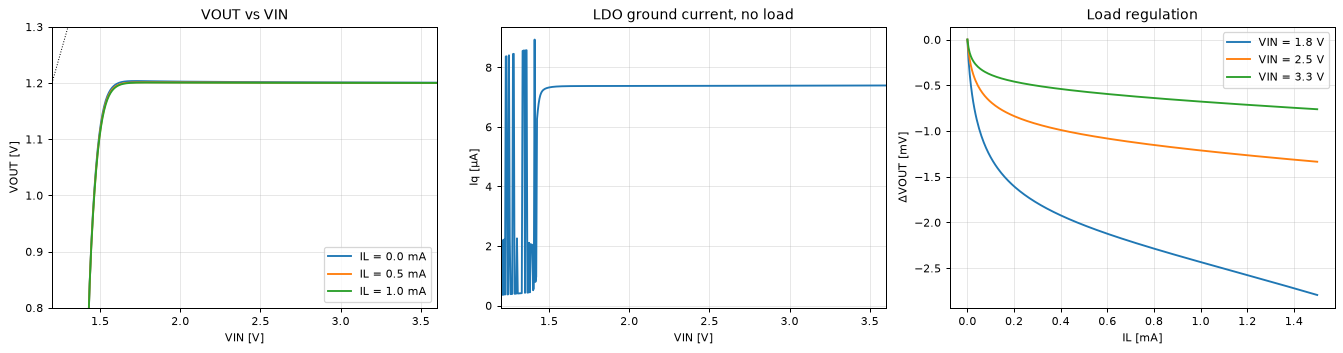

Line regulation (1.8-3.3 V, no load): 1.60 mV/V
Load regulation (0-1 mA): 1.8 V: 2.43 mV/mA, 2.5 V: 1.21 mV/mA, 3.3 V: 0.68 mV/mA


v1 for comparison: dropout 339 mV, line reg 0.19 mV/V, load reg 0.36 mV/mA
Operating points:
             vout      vg    iq_uA
VIN IL                            
1.8 0.000  1.2032  0.9947   7.3771
    0.001  1.2008  0.6431  13.1670
2.5 0.000  1.2016  1.7123   7.3824
    0.001  1.2004  1.3668  13.5231
3.3 0.000  1.2008  2.5290   7.3906
    0.001  1.2001  2.1856  13.7695


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for il in (0, 0.5e-3, 1e-3):
    d = dc_line(P0, il); ax[0].plot(d.vin, d.vout, label=f"IL = {il*1e3:.1f} mA")
ax[0].plot([1.2, 3.6], [1.2, 3.6], "k:", lw=.8); ax[0].set_xlim(1.2, 3.6); ax[0].set_ylim(0.8, 1.3)
ax[0].set(title="VOUT vs VIN", xlabel="VIN [V]", ylabel="VOUT [V]"); ax[0].legend(); ax[0].grid(alpha=.3)
d1 = dc_line(P0, 1e-3)
vnom = np.interp(2.5, d1.vin, d1.vout)
k = np.where(d1.vout >= 0.98*vnom)[0][0]
VDROP = d1.vin[k] - d1.vout[k]
print(f"Dropout @1 mA (VOUT = 98 % of nominal): VIN = {d1.vin[k]:.3f} V, VDO = {VDROP*1e3:.0f} mV")
d0 = dc_line(P0, 0)
m = (d0.vin >= 1.8) & (d0.vin <= 3.3)
LINEREG = (d0.vout[m].max() - d0.vout[m].min()) / 1.5
ax[1].plot(d0.vin, d0.iq*1e6); ax[1].set(title="LDO ground current, no load", xlabel="VIN [V]", ylabel="Iq [µA]")
ax[1].set_xlim(1.2, 3.6); ax[1].grid(alpha=.3)
LOADREG = {}
for vin in (1.8, 2.5, 3.3):
    d = dc_load(P0, vin); ax[2].plot(d.il*1e3, (d.vout - d.vout[0])*1e3, label=f"VIN = {vin} V")
    m = d.il <= 1e-3; LOADREG[vin] = abs(d.vout[m].iloc[-1] - d.vout[0]) / 1.0
ax[2].set(title="Load regulation", xlabel="IL [mA]", ylabel="ΔVOUT [mV]"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()
OP = {(v, il): op_point(P0, v, il) for v in (1.8, 2.5, 3.3) for il in (0, 1e-3)}
IQ0 = max(OP[(v, 0)]["iq"] for v in (1.8, 2.5, 3.3))
print(f"Line regulation (1.8-3.3 V, no load): {LINEREG*1e3:.2f} mV/V")
print("Load regulation (0-1 mA): " + ", ".join(f"{v} V: {LOADREG[v]*1e3:.2f} mV/mA" for v in LOADREG))
# same DC metrics for the v1 design (before/after table)
d1v = dc_line(P_V1, 1e-3); kv = np.where(d1v.vout >= 0.98*np.interp(2.5, d1v.vin, d1v.vout))[0][0]
VDROP_V1 = d1v.vin[kv] - d1v.vout[kv]
d0v = dc_line(P_V1, 0); mv = (d0v.vin >= 1.8) & (d0v.vin <= 3.3); LINEREG_V1 = (d0v.vout[mv].max() - d0v.vout[mv].min()) / 1.5
LOADREG_V1 = max(abs(dc_load(P_V1, v).pipe(lambda d: d.vout[d.il <= 1e-3].iloc[-1] - d.vout[0])) for v in (1.8, 2.5, 3.3))
print(f"v1 for comparison: dropout {VDROP_V1*1e3:.0f} mV, line reg {LINEREG_V1*1e3:.2f} mV/V, load reg {LOADREG_V1*1e3:.2f} mV/mA")
print("Operating points:"); print(pd.DataFrame(OP).T.rename_axis(["VIN", "IL"]).assign(iq_uA=lambda x: x.iq*1e6).drop(columns="iq").round(4))

**Reading the plots.** VOUT tracks VIN until the pass device saturates and then stays flat at 1.2 V. The knee
shifts right with load current. The ground current (≈ 7.4 µA) is the 5 µA bleeder plus the 1 µA tail, 0.25 µA reference branch,
0.75 µA buffer stack and 0.25 µA buffer-bias branch, and it barely depends on VIN. The DC loop gain is ≈ 81–84 dB (Section 9.2). Load regulation is 0.7–2.4 mV/mA and is worst at VIN = 1.8 V,
where the pass device has the least headroom. v1 reached 0.36 mV/mA; this is one of the costs of v2 listed in Section 13.

### 9.2 Loop stability (open-loop gain, loop broken at the error-amplifier gate)

The loop is opened at the **gate of MN1**. It is a pure capacitive input, so breaking it there is exact: the DC operating point is
kept by a unity buffer followed by a 10⁹ s low-pass, and the AC test signal is injected in series. T(s) = −v(out)/v(fb). This is
the high-impedance-node special case of Middlebrook's method [7]. Tian's general method is not needed because the node has no loading.

v2 has a second, **local** loop (VOUT → Cf → buffer → `vg` → pass device → VOUT) that stays closed in this measurement.
A Bode plot of the global loop cannot prove that a closed inner loop is stable. We therefore also apply small load steps
(10 % or 2 µA, 100 ns edges) at every load and CL and measure the ringing. An unstable or poorly damped inner loop would show up there.

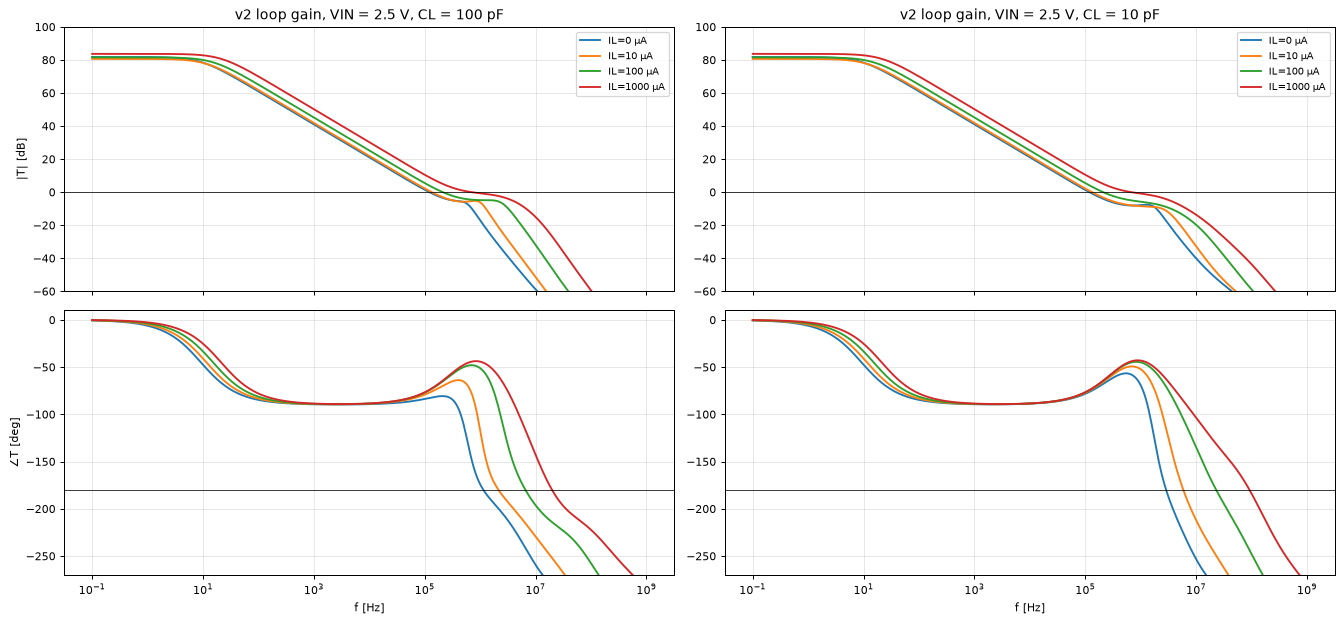

 CL_pF  IL_uA  A0_dB  UGF_kHz  PM_deg  v1_UGF_kHz  v1_PM_deg
 100.0    0.0   81.7    121.1    97.2        84.2       67.3
 100.0   10.0   80.6    133.1   104.0       103.9       77.1
 100.0  100.0   81.5    210.2   114.7       190.0       85.3
 100.0 1000.0   83.6    690.1   135.6       400.0       87.6
  10.0    0.0   81.7    118.2   103.6        89.7       85.0
  10.0   10.0   80.6    131.4   106.3       106.0       87.2
  10.0  100.0   81.5    208.7   115.2       190.5       88.8
  10.0 1000.0   83.6    663.0   135.9       400.2       89.1

Hand analysis (no load, 100 pF): v1 UGF = 76 kHz, PM = 71 deg | v2 UGF = 105 kHz, PM >= 57 deg   ->   simulated v1: 84 kHz / 67 deg, v2: 121 kHz / 97 deg


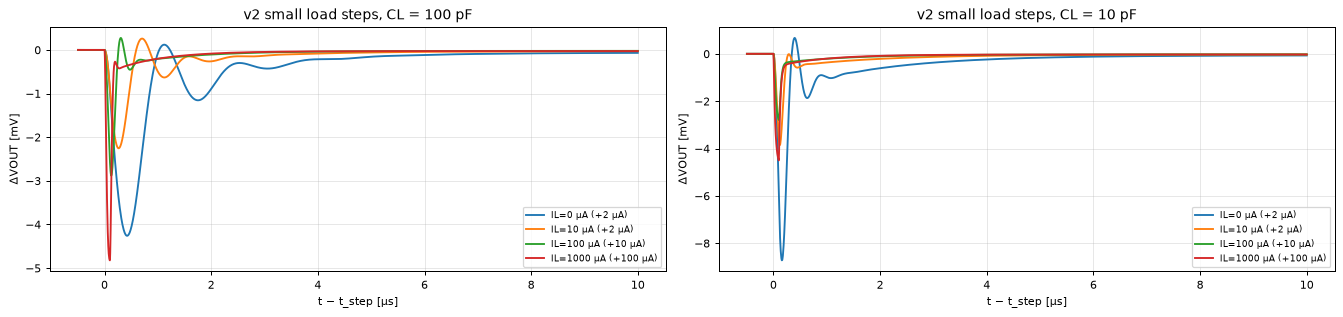

 CL_pF  IL_uA  dip_mV  overshoot_pct
 100.0    0.0    4.20           4.35
 100.0   10.0    2.23          12.93
 100.0  100.0    2.86          10.36
 100.0 1000.0    4.80           0.00
  10.0    0.0    8.66           8.49
  10.0   10.0    3.83           0.42
  10.0  100.0    2.77           0.00
  10.0 1000.0    4.47           0.00


In [9]:
fig, ax = plt.subplots(2, 2, figsize=(15, 7), sharex="col")
LG = []
for cl, col in ((100e-12, 0), (10e-12, 1)):
    for il in (0, 10e-6, 100e-6, 1e-3):
        r = loop(P0, 2.5, il, cl)
        ax[0, col].semilogx(r["f"], r["mag"], label=f"IL={il*1e6:g} µA")
        ax[1, col].semilogx(r["f"], r["ph"])
        r1 = loop(P_V1, 2.5, il, cl)
        LG.append(dict(CL_pF=cl*1e12, IL_uA=il*1e6, A0_dB=r["a0"], UGF_kHz=r["fu"]/1e3, PM_deg=r["pm"],
                       v1_UGF_kHz=r1["fu"]/1e3, v1_PM_deg=r1["pm"]))
    ax[0, col].set_title(f"v2 loop gain, VIN = 2.5 V, CL = {cl*1e12:.0f} pF"); ax[0, col].axhline(0, color="k", lw=.6)
    ax[1, col].axhline(-180, color="k", lw=.6); ax[1, col].set_xlabel("f [Hz]")
    ax[0, col].set_ylim(-60, 100); ax[1, col].set_ylim(-270, 10); ax[0, col].legend(fontsize=8)
    for a in ax[:, col]: a.grid(True, which="both", alpha=.3)
ax[0, 0].set_ylabel("|T| [dB]"); ax[1, 0].set_ylabel("∠T [deg]")
plt.tight_layout(); plt.show()
LG = pd.DataFrame(LG); print(LG.round(1).to_string(index=False))
print(f"\nHand analysis (no load, 100 pF): v1 UGF = {H1['ugf']/1e3:.0f} kHz, PM = {H1['pm']:.0f} deg | "
      f"v2 UGF = {H2['ugf']/1e3:.0f} kHz, PM >= {H2['pm']:.0f} deg   ->   simulated v1: {LG.v1_UGF_kHz[0]:.0f} kHz / {LG.v1_PM_deg[0]:.0f} deg,"
      f" v2: {LG.UGF_kHz[0]:.0f} kHz / {LG.PM_deg[0]:.0f} deg")
# small-step ringing test (inner + outer loop, large-signal operating points included)
SS = []
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
for cl, a in ((100e-12, ax[0]), (10e-12, ax[1])):
    for il in (0, 10e-6, 100e-6, 1e-3):
        d, s = small_step(P0, il, None, cl)
        m = (d.t > 19.5e-6) & (d.t < 30e-6)
        a.plot((d.t[m]-20e-6)*1e6, (d.vout[m]-d.vout[m].iloc[0])*1e3, label=f"IL={il*1e6:g} µA (+{max(0.1*il, 2e-6)*1e6:g} µA)")
        SS.append(dict(CL_pF=cl*1e12, IL_uA=il*1e6, **s))
    a.set(title=f"v2 small load steps, CL = {cl*1e12:.0f} pF", xlabel="t − t_step [µs]", ylabel="ΔVOUT [mV]"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
SS = pd.DataFrame(SS); print(SS.round(2).to_string(index=False))

**Key insight, read carefully.** In v1 the worst case was no load with the largest CL (PM ≈ 67°), because the non-dominant pole
gm_pass/CL is lowest there. In v2 the *global* loop-gain plot shows phase margins above 90°. The current buffers turn the Miller
feed-forward right-half-plane zero into a left-half-plane zero, and that zero adds phase near the crossover. This is the same reason
Ahuja compensation is used in low-power op-amps. **However, that number overstates the real damping.** The small-step test,
which also includes the inner loop, shows up to ≈ 13 % overshoot at light load at tt (10–100 µA, 100 pF), and Section 11 finds ≈ 17 % in the worst PVT corner
(ff, −40 °C). For a second-order loop that corresponds to a phase margin of ≈ 51°, which is *lower* than v1's 63°. So the honest
statement is: v2 is stable with less damping margin than v1, not "more than 90°".
The step responses settle without sustained ringing at every load and CL, and Section 11 repeats this test over PVT. The hand formula
(UGF ≈ gm1/(2π·C_eff)) predicts the v1 → v2 trend in UGF. The hand PM for v2 ignores the LHP zero and the inner loop, so treat it only as a rough estimate.

**Why v1 could not be fixed by re-sizing (v1 design space).** The sweep below varies Cc, tail current and bleeder of the *v1*
topology. The 100 ns droop barely depends on Cc and only improves by spending static current on the bleeder:

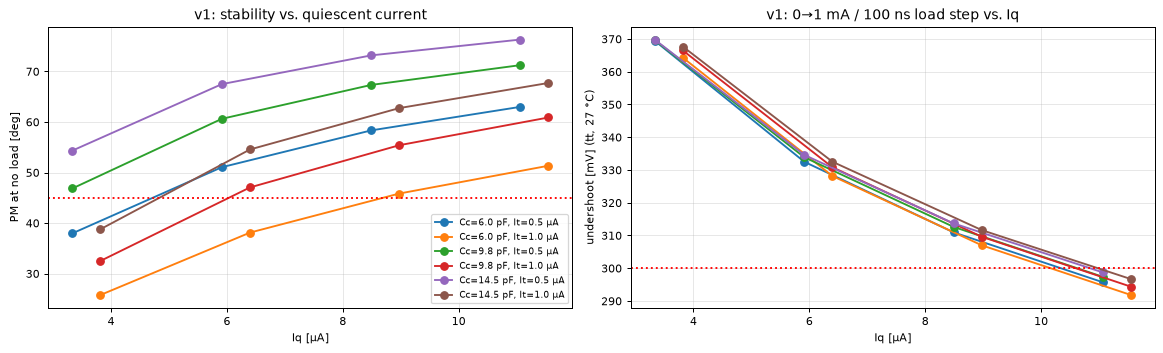

 Cc_pF  It_uA  Ibleed_uA  Iq_uA  PM_noload  UGF_kHz  undershoot_mV
   6.0    0.5        2.5    3.3       38.0     86.3          369.5
   6.0    0.5        5.0    5.9       51.1    110.6          332.5
   6.0    0.5        7.5    8.5       58.3    125.8          310.9
   6.0    0.5       10.0   11.1       63.0    137.1          295.7
   6.0    1.0        2.5    3.8       25.8    126.7          364.3
   6.0    1.0        5.0    6.4       38.1    167.2          328.2
   6.0    1.0        7.5    9.0       45.8    193.3          307.0
   6.0    1.0       10.0   11.5       51.3    212.2          291.8
   9.8    0.5        2.5    3.3       46.8     62.8          369.7
   9.8    0.5        5.0    5.9       60.6     76.3          333.9
   9.8    0.5        7.5    8.5       67.3     84.2          312.6
   9.8    0.5       10.0   11.1       71.3     90.1          297.4
   9.8    1.0        2.5    3.8       32.5     95.9          366.5
   9.8    1.0        5.0    6.4       47.0    121.6          3

In [10]:
import itertools
def tradeoff(a):
    cs, mt, mbl = a; P = dict(P_V1, Cc_side=cs, mt=mt, mbl=mbl)
    l0 = loop(P, 2.5, 0); _, r = tran_load(P, 2.5, 0, 1e-3, 100e-9)
    return dict(Cc_pF=round(2e-3*cs**2, 1), It_uA=mt*P0["Ib"]*1e6, Ibleed_uA=mbl*P0["Ib"]*1e6,
                Iq_uA=op_point(P, 2.5, 0)["iq"]*1e6, PM_noload=l0["pm"], UGF_kHz=l0["fu"]/1e3,
                undershoot_mV=(r["vpre"]-r["vmin"])*1e3)
TR = pd.DataFrame(pmap(tradeoff, list(itertools.product([55, 70, 85], [2, 4], [10, 20, 30, 40]))))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (cc, it), g in TR.groupby(["Cc_pF", "It_uA"]):
    ax[0].plot(g.Iq_uA, g.PM_noload, "o-", label=f"Cc={cc} pF, It={it:.1f} µA")
    ax[1].plot(g.Iq_uA, g.undershoot_mV, "o-")
ax[0].axhline(45, color="r", ls=":"); ax[0].set(xlabel="Iq [µA]", ylabel="PM at no load [deg]", title="v1: stability vs. quiescent current")
ax[1].axhline(300, color="r", ls=":"); ax[1].set(xlabel="Iq [µA]", ylabel="undershoot [mV] (tt, 27 °C)", title="v1: 0→1 mA / 100 ns load step vs. Iq")
ax[0].legend(fontsize=7); [a.grid(alpha=.3) for a in ax]; plt.tight_layout(); plt.show()
print(TR.round(1).to_string(index=False))

In v1, even 11 µA of Iq only reaches ≈ 295 mV at 27 °C, and the hot corner is ≈ 80 mV worse. The droop follows the
pass-gate swing ≈ n·U_T·ln(I_max/I_bleed) + strong-inversion overdrive, because a capacitive divider has a gain of at most 1.

### 9.3 PSRR (v1 vs v2)

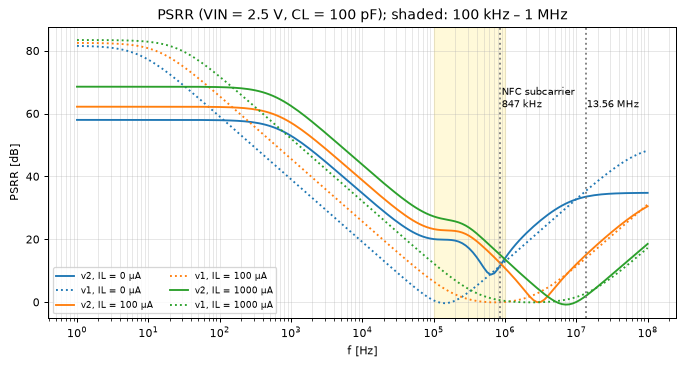

PSRR @1 kHz (worst load) = 52.9 dB
worst PSRR in 100 kHz-1 MHz: v1 -0.4 dB -> v2 8.7 dB;  @847 kHz: v1 -0.1 dB -> v2 11.4 dB


In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
PSRR, PSRR_V1 = {}, {}
for il, c in ((0, "tab:blue"), (100e-6, "tab:orange"), (1e-3, "tab:green")):
    d = psrr(P0, 2.5, il); ax.semilogx(d.f, d.psrr, color=c, label=f"v2, IL = {il*1e6:g} µA"); PSRR[il] = d
    d1 = psrr(P_V1, 2.5, il); ax.semilogx(d1.f, d1.psrr, ":", color=c, label=f"v1, IL = {il*1e6:g} µA"); PSRR_V1[il] = d1
ax.axvspan(1e5, 1e6, color="gold", alpha=.15)
ax.axvline(847e3, color="gray", ls=":"); ax.text(900e3, 62, "NFC subcarrier\n847 kHz", fontsize=8)
ax.axvline(13.56e6, color="gray", ls=":"); ax.text(14e6, 62, "13.56 MHz", fontsize=8)
ax.set(xlabel="f [Hz]", ylabel="PSRR [dB]", title="PSRR (VIN = 2.5 V, CL = 100 pF); shaded: 100 kHz – 1 MHz"); ax.grid(True, which="both", alpha=.3)
ax.legend(fontsize=7, ncol=2); plt.show()
band = lambda d: d.psrr[(d.f >= 1e5) & (d.f <= 1e6)].min()
PSRR1K = min(np.interp(1e3, d.f, d.psrr) for d in PSRR.values())
PSRRBAND = min(band(d) for d in PSRR.values()); PSRRBAND_V1 = min(band(d) for d in PSRR_V1.values())
PSRR847 = min(np.interp(8.47e5, d.f, d.psrr) for d in PSRR.values()); PSRR847_V1 = min(np.interp(8.47e5, d.f, d.psrr) for d in PSRR_V1.values())
print(f"PSRR @1 kHz (worst load) = {PSRR1K:.1f} dB")
print(f"worst PSRR in 100 kHz-1 MHz: v1 {PSRRBAND_V1:.1f} dB -> v2 {PSRRBAND:.1f} dB;  @847 kHz: v1 {PSRR847_V1:.1f} dB -> v2 {PSRR847:.1f} dB")

**Reading the plot.** At low frequency PSRR ≈ loop gain (> 75 dB) and falls 20 dB/dec above the dominant pole. In v1 it
reaches ≈ 0 dB between ≈ 50 kHz and 1 MHz: the loop has no gain left, there is no large output capacitor, and the pass gate is
held by Cc to VOUT instead of following VIN. Two changes in v2 help. (1) The direct Miller capacitor is 5× smaller, so the
pass Cgs (to VIN) holds `vg` closer to VIN. (2) The feed-forward capacitor Cff injects Cff·dVIN/dt into `vg` through the NMOS buffer,
which makes |VSG| of the pass device less sensitive to ripple. Cbp keeps the PMOS-buffer bias from copying VIN ripple onto VOUT through Cfp.
The improvement is real but modest (≈ +9 dB in the band). A larger Cff would add more PSRR but it loads the buffer source
and increases the load-step droop. That trade-off is shown in Section 9.4. An RC pre-filter on VIN remains the simplest way to get more.

### 9.4 Load transient (v1 vs v2) and the transient-enhancement trade-off

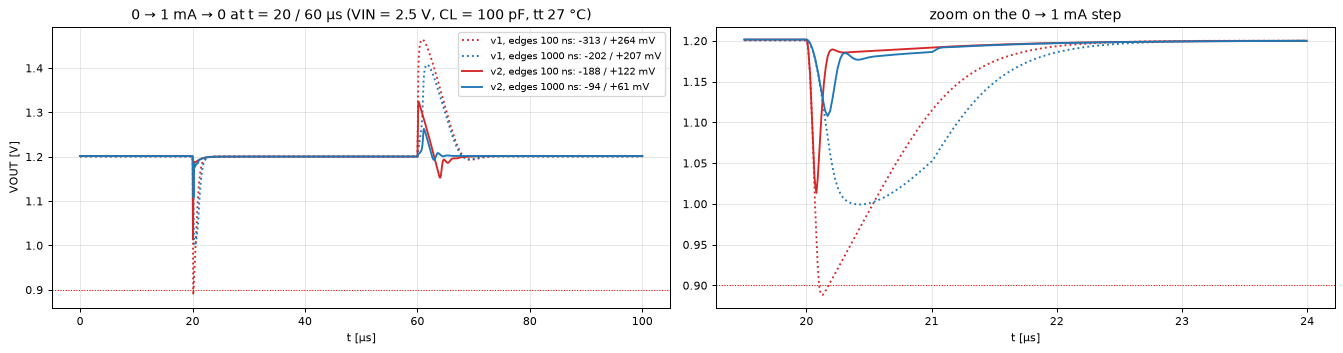

Transient FoM (Hazucha) = CL*dV/dI * Iq/dI:  v1 266 ps  ->  v2 139 ps  (lower is better)
hand droop model (Section 7, item 7): v1 366 mV, v2 220 mV;  simulated: v1 313 mV, v2 188 mV


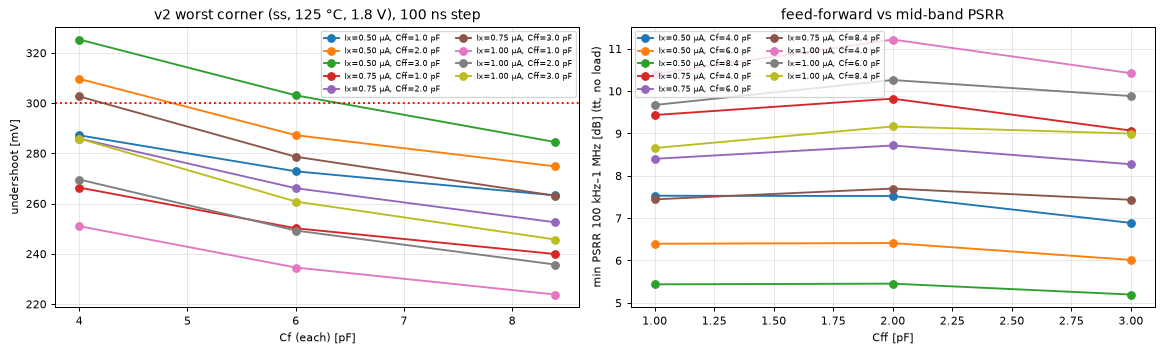

 Ix_uA  Cf_pF  Cff_pF  undershoot_mV  overshoot_mV  psrr_band_dB  Iq_uA  area_um2
   0.5    4.0     1.0          287.2         188.3           7.5    7.1      5918
   0.5    4.0     2.0          309.7         189.0           7.5    7.1      6458
   0.5    4.0     3.0          325.3         189.6           6.9    7.1      6955
   0.5    6.0     1.0          272.8         185.5           6.4    7.1      7918
   0.5    6.0     2.0          287.2         185.9           6.4    7.1      8458
   0.5    6.0     3.0          303.1         186.3           6.0    7.1      8955
   0.5    8.4     1.0          263.3         183.9           5.4    7.1     10318
   0.5    8.4     2.0          274.8         184.1           5.5    7.1     10858
   0.5    8.4     3.0          284.5         184.3           5.2    7.1     11355
   0.8    4.0     1.0          266.4         173.3           9.4    7.4      5918
   0.8    4.0     2.0          285.9         174.4           9.8    7.4      6458
   0.8    4.0   

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
TL, TL_V1 = {}, {}
for P_, nm, ls in ((P_V1, "v1", ":"), (P0, "v2", "-")):
    for tr, c in ((100e-9, "tab:red"), (1e-6, "tab:blue")):
        d, r = tran_load(P_, 2.5, 0, 1e-3, tr)
        (TL if nm == "v2" else TL_V1)[tr] = r
        ax[0].plot(d.t*1e6, d.vout, ls, color=c, label=f"{nm}, edges {tr*1e9:g} ns: -{(r['vpre']-r['vmin'])*1e3:.0f} / +{(r['vmax']-r['vpre'])*1e3:.0f} mV")
        m = (d.t > 19.5e-6) & (d.t < 24e-6); ax[1].plot(d.t[m]*1e6, d.vout[m], ls, color=c)
ax[0].set(title="0 → 1 mA → 0 at t = 20 / 60 µs (VIN = 2.5 V, CL = 100 pF, tt 27 °C)", xlabel="t [µs]", ylabel="VOUT [V]")
ax[1].set(title="zoom on the 0 → 1 mA step", xlabel="t [µs]")
for a in ax: a.axhline(0.9, color="r", ls=":", lw=.8); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
FOM_T = 100e-12 * (TL[100e-9]["vpre"] - TL[100e-9]["vmin"]) / 1e-3 * IQ0 / 1e-3
IQ0_V1 = op_point(P_V1, 3.3, 0)["iq"]
FOM_T_V1 = 100e-12 * (TL_V1[100e-9]["vpre"] - TL_V1[100e-9]["vmin"]) / 1e-3 * IQ0_V1 / 1e-3
print(f"Transient FoM (Hazucha) = CL*dV/dI * Iq/dI:  v1 {FOM_T_V1*1e12:.0f} ps  ->  v2 {FOM_T*1e12:.0f} ps  (lower is better)")
print(f"hand droop model (Section 7, item 7): v1 {HAND_DROOP['v1']*1e3:.0f} mV, v2 {HAND_DROOP['v2']*1e3:.0f} mV;"
      f"  simulated: v1 {(TL_V1[100e-9]['vpre']-TL_V1[100e-9]['vmin'])*1e3:.0f} mV, v2 {(TL[100e-9]['vpre']-TL[100e-9]['vmin'])*1e3:.0f} mV")

# booster sizing sweep at the worst corner (ss, 125 C, VIN 1.8 V): buffer bias Ix, Cf, Cff
def boost_job(a):
    mx, cfs, cffs = a; P = dict(P0, mx=mx, Cf_side=cfs, Cff_side=cffs)
    _, r = tran_load(P, 1.8, 0, 1e-3, 100e-9, corner="ss", temp=125)
    return dict(Ix_uA=mx*P0["Ib"]*1e6, Cf_pF=round(2e-3*cfs**2, 1), Cff_pF=round(2e-3*cffs**2, 1),
                undershoot_mV=(r["vpre"]-r["vmin"])*1e3, overshoot_mV=(r["vmax"]-r["vpre"])*1e3,
                psrr_band_dB=psrr_band(P, 0), Iq_uA=op_point(P, 3.3, 0)["iq"]*1e6, area_um2=mim_area(P))
BS = pd.DataFrame(pmap(boost_job, list(itertools.product([2, 3, 4], [45, 55, 65], [22, 32, 39]))))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (ix, cff), g in BS.groupby(["Ix_uA", "Cff_pF"]):
    ax[0].plot(g.Cf_pF, g.undershoot_mV, "o-", label=f"Ix={ix:.2f} µA, Cff={cff} pF")
for (ix, cf), g in BS.groupby(["Ix_uA", "Cf_pF"]):
    ax[1].plot(g.Cff_pF, g.psrr_band_dB, "o-", label=f"Ix={ix:.2f} µA, Cf={cf} pF")
ax[0].axhline(300, color="r", ls=":"); ax[0].set(xlabel="Cf (each) [pF]", ylabel="undershoot [mV]", title="v2 worst corner (ss, 125 °C, 1.8 V), 100 ns step")
ax[1].set(xlabel="Cff [pF]", ylabel="min PSRR 100 kHz–1 MHz [dB] (tt, no load)", title="feed-forward vs mid-band PSRR")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()
print(BS.round(1).to_string(index=False))

**Reading the plots.** Left: v1 (dotted) versus v2 (solid). In v2 the gate gets the extra charge through the buffers within
tens of ns, so the undershoot drops by ≈ 40 % at 27 °C and by ≈ 130 mV in the worst PVT corner. Recovery is also faster, because `vg` carries only ≈ 1/4 of the v1 capacitance.
Bottom sweep: undershoot falls with larger Cf and larger buffer bias Ix (the buffer source has to move less, logarithmically).
A larger feed-forward capacitor Cff improves mid-band PSRR but costs droop, because Cff also loads the buffer source.
The chosen point (Ix = 0.75 µA, Cf = 6 pF, Cff = 2 pF) keeps ≥ 30 mV of droop margin at the worst corner with a moderate MIM
area (total LDO MIM ≈ 8,500 µm² ≈ 92 × 92 µm, versus 4,900 µm² in v1).

### 9.5 Line transient

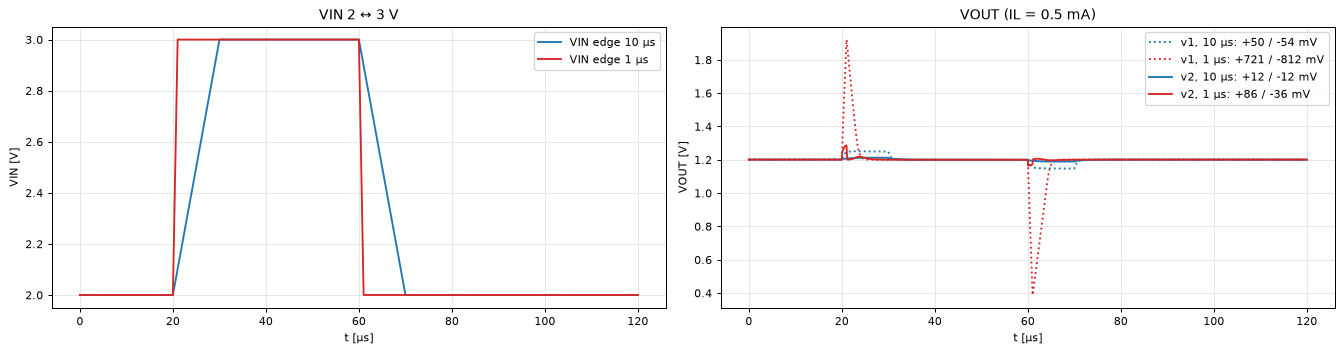

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
TLINE, TLINE_V1 = {}, {}
for P_, nm, ls in ((P_V1, "v1", ":"), (P0, "v2", "-")):
    for tr, c in ((10e-6, "tab:blue"), (1e-6, "tab:red")):
        d, r = tran_line(P_, 2.0, 3.0, tr, 0.5e-3, tstop=120e-6); (TLINE if nm == "v2" else TLINE_V1)[tr] = r
        if nm == "v2": ax[0].plot(d.t*1e6, d.vin, color=c, label=f"VIN edge {tr*1e6:g} µs")
        ax[1].plot(d.t*1e6, d.vout, ls, color=c, label=f"{nm}, {tr*1e6:g} µs: +{(r['vmax']-r['vpre'])*1e3:.0f} / -{(r['vpre']-r['vmin'])*1e3:.0f} mV")
ax[0].set(title="VIN 2 ↔ 3 V", xlabel="t [µs]", ylabel="VIN [V]"); ax[1].set(title="VOUT (IL = 0.5 mA)", xlabel="t [µs]", ylabel="VOUT [V]")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Key insight: the slew-rate limit, and how v2 removes most of it.** In v1, a 1 V / 1 µs edge cannot be followed by the gate:
the error amplifier slews `vg` at only It/(Cc + Cg) ≈ 48 mV/µs while Cc holds `vg` to VOUT, so |VSG| grows with VIN and VOUT
overshoots by ≈ 0.7 V. This is why Section 7 sizes **C_st from the LDO slew rate**. In v2, the feed-forward capacitor delivers the
gate charge Cff·dVIN/dt directly, and the direct Miller capacitor is 5× smaller, so `vg` follows VIN without waiting for the amplifier.
Both line steps improve by roughly a factor of 4–7. The C_st rule from Section 7 is kept as a conservative system guideline.

### 9.6 Output noise (information only, no spec)

A tag core with a sensor interface or ADC on the same 1.2 V rail also cares about noise. The LDO is biased in weak inversion
with sub-µA branch currents, so its noise needs checking even though no spec is set. ngspice's `.noise` analysis gives the
output noise density with the transistor (thermal + flicker) and poly-resistor noise of the SKY130 models. The ideal VREF and Iref
sources are noiseless, so a real reference adds its own noise on top (see Limitations).

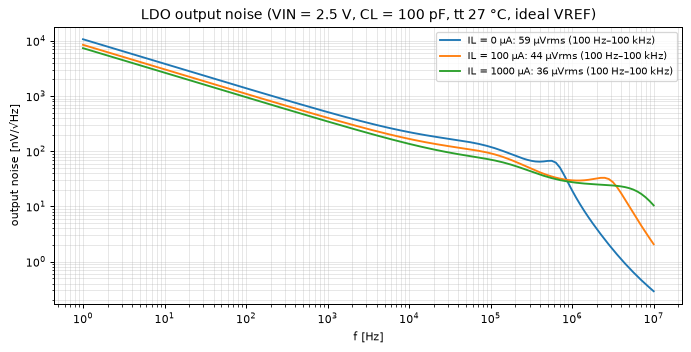

IL =      0 uA: integrated 100 Hz-100 kHz = 59 uVrms, 10 Hz-1 MHz = 86 uVrms, density @1 kHz = 514 nV/rtHz
IL =    100 uA: integrated 100 Hz-100 kHz = 44 uVrms, 10 Hz-1 MHz = 63 uVrms, density @1 kHz = 403 nV/rtHz
IL =   1000 uA: integrated 100 Hz-100 kHz = 36 uVrms, 10 Hz-1 MHz = 53 uVrms, density @1 kHz = 347 nV/rtHz


In [14]:
def noise(P, vin=2.5, il=0.0, cl=100e-12, corner="tt", temp=27):
    tag = _t(P, "noise", vin, il, cl, corner, temp)
    body = f"Vin vin 0 dc {vin} ac 1\nXldo vin vout vout vref 0 ldo\nCL vout 0 {cl}\nIl vout 0 {il}\n"
    ctl = f"noise v(vout) Vin dec 20 1 10Meg\nsetplot noise1\nwrdata {tag}.dat onoise_spectrum"
    spice(tb(P, body, ctl, corner, temp), tag)
    d = wrdata(tag); d.columns = ["f", "vn"]; return d

def vrms(d, f1=100, f2=100e3):
    m = (d.f >= f1) & (d.f <= f2)
    trap = getattr(np, "trapezoid", None) or np.trapz
    return np.sqrt(trap(d.vn[m]**2, d.f[m]))

fig, ax = plt.subplots(figsize=(9, 4))
NOISE = {}
for il, c in ((0, "tab:blue"), (100e-6, "tab:orange"), (1e-3, "tab:green")):
    d = noise(P0, 2.5, il); NOISE[il] = d
    ax.loglog(d.f, d.vn*1e9, color=c, label=f"IL = {il*1e6:g} µA: {vrms(d)*1e6:.0f} µVrms (100 Hz–100 kHz)")
ax.set(xlabel="f [Hz]", ylabel="output noise [nV/√Hz]", title="LDO output noise (VIN = 2.5 V, CL = 100 pF, tt 27 °C, ideal VREF)")
ax.grid(True, which="both", alpha=.3); ax.legend(fontsize=8); plt.show()
for il, d in NOISE.items():
    print(f"IL = {il*1e6:6g} uA: integrated 100 Hz-100 kHz = {vrms(d)*1e6:.0f} uVrms, 10 Hz-1 MHz = {vrms(d, 10, 1e6)*1e6:.0f} uVrms,"
          f" density @1 kHz = {np.interp(1e3, d.f, d.vn)*1e9:.0f} nV/rtHz")

**Reading the plot.** The low-frequency plateau is the error-amplifier noise (flicker plus the thermal noise of the weak-inversion pair and mirror),
gained by the closed loop to the output. Above the loop bandwidth the noise rolls off with the output impedance. The result is ≈ 36–59 µVrms
(100 Hz–100 kHz), worst at no load where the loop gain-bandwidth is lowest. One LSB of a 12-bit ADC with a 1.2 V full scale is 293 µV, so a
≤ 12-bit sensor ADC can share this rail at tt. A higher-resolution ADC, or the noise of a real nano-power reference added on top, would need a
separate filtered reference.

<a name="por"></a>
## 10. Power-on-reset and system start-up

### 10.1 Threshold and hysteresis (slow triangular VIN sweep)

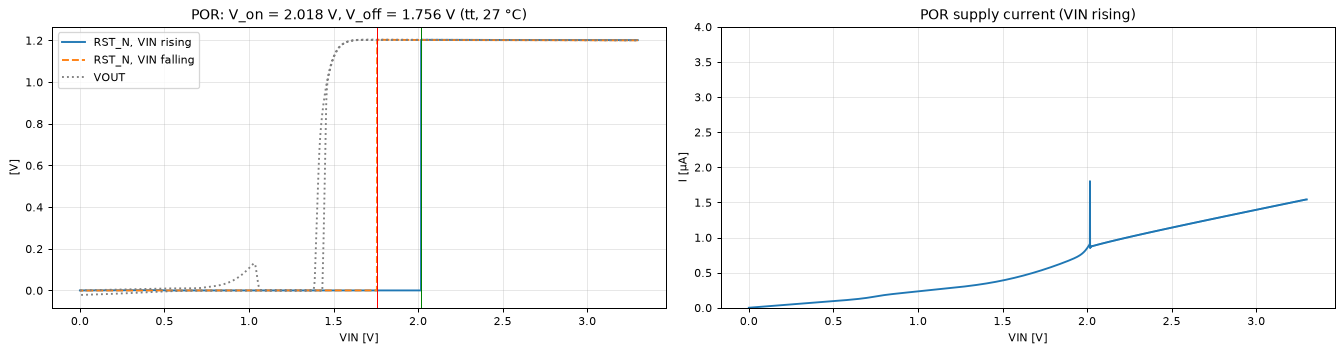

hand analysis: V_on = 1.92 V, V_off = 1.72 V   |  simulated: 2.018 / 1.756 V  (the hand model assumes INV1 trips at VIN/2 and a constant Rpu current)
POR current: 2.0 V: 0.85 µA, 3.3 V: 1.54 µA (transient peak during switching excluded)


In [15]:
d, r = por_sweep(P0)
POR_NOM = r
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(d.vin[d.t < 2e-3], d.rstn[d.t < 2e-3], label="RST_N, VIN rising")
ax[0].plot(d.vin[d.t >= 2e-3], d.rstn[d.t >= 2e-3], "--", label="RST_N, VIN falling")
ax[0].plot(d.vin, d.vout, ":", color="gray", label="VOUT")
ax[0].axvline(r["von"], color="g", lw=.8); ax[0].axvline(r["voff"], color="r", lw=.8)
ax[0].set(title=f"POR: V_on = {r['von']:.3f} V, V_off = {r['voff']:.3f} V (tt, 27 °C)", xlabel="VIN [V]", ylabel="[V]")
ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(d.vin[d.t < 2e-3], d.iin[d.t < 2e-3]*1e6)
ax[1].set(title="POR supply current (VIN rising)", xlabel="VIN [V]", ylabel="I [µA]"); ax[1].set_ylim(0, 4); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
up = d[(d.t < 2e-3)]
IPOR = {v: np.interp(v, up.vin, up.iin) for v in (2.0, 3.3)}
print(f"hand analysis: V_on = {HAND['von']:.2f} V, V_off = {HAND['voff']:.2f} V   |  simulated: {r['von']:.3f} / {r['voff']:.3f} V"
      "  (the hand model assumes INV1 trips at VIN/2 and a constant Rpu current)")
print("POR current: " + ", ".join(f"{v} V: {i*1e6:.2f} µA" for v, i in IPOR.items()), "(transient peak during switching excluded)")

### 10.2 ZTC biasing of the detector: why W = 0.7 µm

The plot sweeps the detector width (L = 20 µm) and shows the rising threshold V_on over temperature in the three main corners.
A narrow device (high current density, above ZTC) gives a positive temperature coefficient, a wide device (below ZTC) a
negative one. W ≈ 0.7 µm cancels the two.

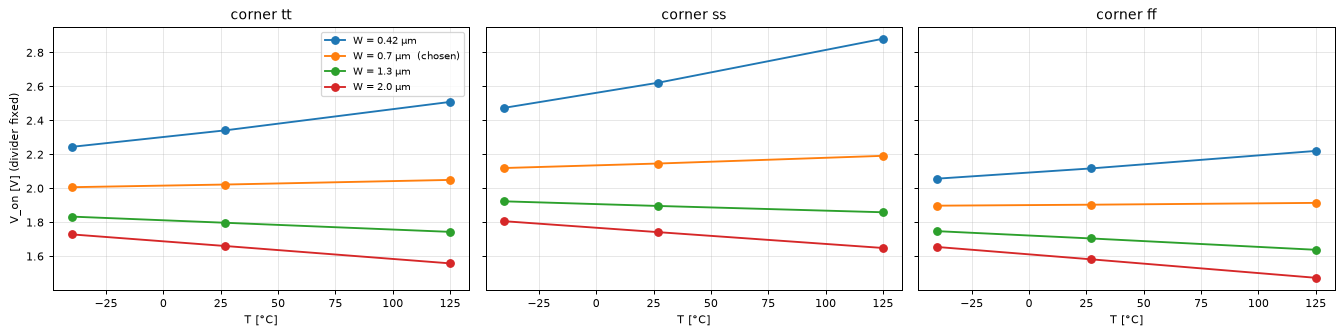

corner     ff                   ss                   tt              
T        -40     27     125   -40     27     125   -40     27     125
Wd                                                                   
0.42    2.057  2.117  2.220  2.474  2.622  2.881  2.244  2.341  2.509
0.70    1.898  1.903  1.914  2.119  2.146  2.191  2.006  2.022  2.049
1.30    1.747  1.704  1.638  1.923  1.896  1.859  1.833  1.797  1.743
2.00    1.654  1.582  1.473  1.806  1.742  1.648  1.728  1.660  1.558


In [16]:
def ztc_job(a):
    wd, T, c = a; P = dict(P0, Wd=wd)
    _, r = por_sweep(P, c, T, tramp=0.4e-3); return dict(Wd=wd, T=T, corner=c, von=r["von"])
ZT = pd.DataFrame(pmap(ztc_job, list(itertools.product([0.42, 0.7, 1.3, 2.0], [-40, 27, 125], ["tt", "ss", "ff"]))))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, c in zip(ax, ["tt", "ss", "ff"]):
    for wd, g in ZT[ZT.corner == c].groupby("Wd"):
        a.plot(g["T"], g.von, "o-", label=f"W = {wd} µm" + ("  (chosen)" if wd == P0["Wd"] else ""))
    a.set(title=f"corner {c}", xlabel="T [°C]"); a.grid(alpha=.3)
ax[0].set_ylabel("V_on [V] (divider fixed)"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(ZT.pivot_table(index="Wd", columns=["corner", "T"], values="von").round(3).to_string())

### 10.3 System start-up with an RF harvester: intermittent (burst-mode) operation

Harvester = 300 µA current source charging C_st = 47 nF, soft clamp at 3.3 V. The tag core draws 1 mA from VOUT
when RST_N is high, with a 1 µs current ramp (clock start-up). Because 1 mA > 300 µA, continuous operation is impossible.
The hysteresis turns it into stable **bursts**: charge to V_on, run until V_off, repeat. A POR without hysteresis
would oscillate at the threshold instead.

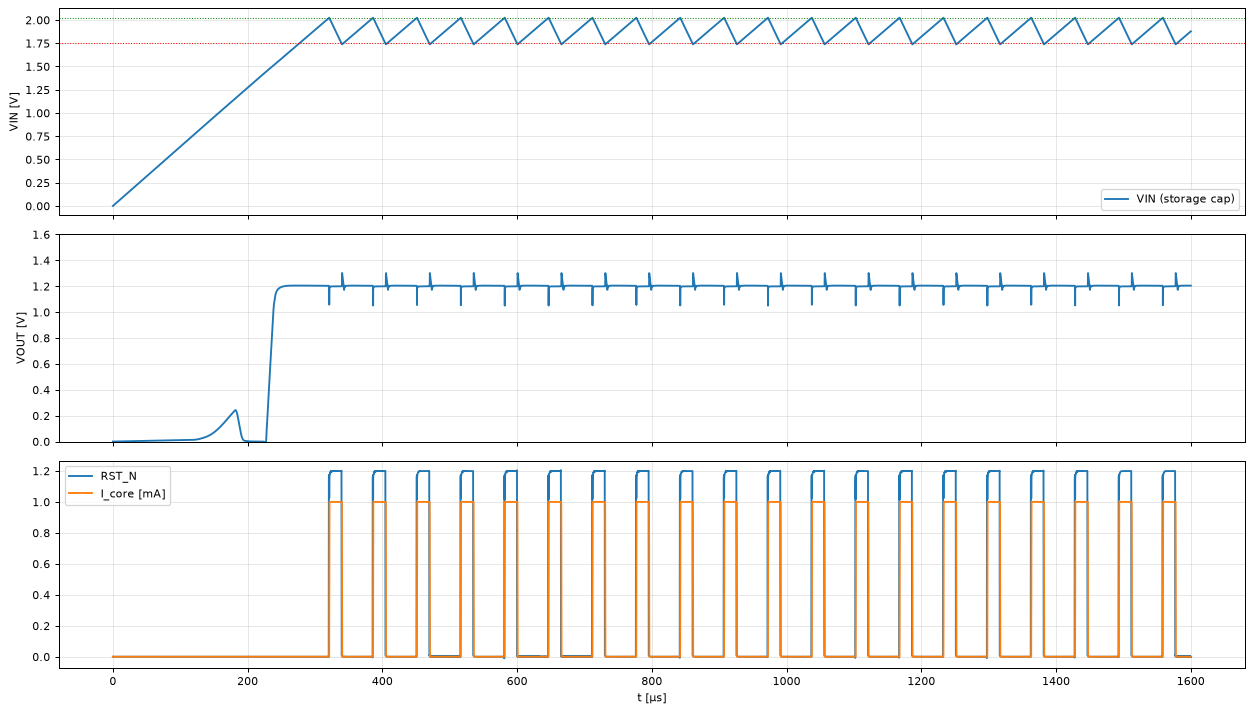

first RST release at 320 µs, VOUT 1 µs before release = 1.204 V; bursts: 20; duty cycle ≈ 30 % (≈ I_harv/I_core = 30 %)
min VOUT while the core is active (includes the wake-up droop of every burst): 1.050 V; VIN range in burst mode: 1.738 – 2.025 V


In [17]:
d, r = system_startup(P0, iharv=300e-6, cst=47e-9, iload=1e-3, tstop=1.6e-3)
fig, ax = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
ax[0].plot(d.t*1e6, d.vin, label="VIN (storage cap)"); ax[0].axhline(POR_NOM["von"], color="g", ls=":", lw=.8)
ax[0].axhline(POR_NOM["voff"], color="r", ls=":", lw=.8); ax[0].set_ylabel("VIN [V]"); ax[0].legend()
ax[1].plot(d.t*1e6, d.vout, label="VOUT"); ax[1].set_ylabel("VOUT [V]"); ax[1].set_ylim(0, 1.6)
ax[2].plot(d.t*1e6, d.rstn, label="RST_N"); ax[2].plot(d.t*1e6, d.iload*1e3, label="I_core [mA]"); ax[2].legend()
ax[2].set_xlabel("t [µs]")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
act = d.rstn > 0.6
edges = np.where(np.diff(act.astype(int)) == 1)[0]
t_release = d.t[edges[0]] if len(edges) else np.nan
vout_at_release = np.interp(t_release - 1e-6, d.t, d.vout)
SYS = dict(t_release=t_release, vout_at_release=vout_at_release, n_bursts=len(edges),
           vout_min_active=d.vout[act & (d.t > t_release + 5e-6)].min() if len(edges) else np.nan,
           duty=act[d.t > t_release].mean())
print(f"first RST release at {t_release*1e6:.0f} µs, VOUT 1 µs before release = {vout_at_release:.3f} V; bursts: {len(edges)};"
      f" duty cycle ≈ {SYS['duty']*100:.0f} % (≈ I_harv/I_core = 30 %)")
print(f"min VOUT while the core is active (includes the wake-up droop of every burst): {SYS['vout_min_active']:.3f} V;"
      f" VIN range in burst mode: {d.vin[d.t > t_release].min():.3f} – {d.vin[d.t > t_release].max():.3f} V")

**Reading the plot.** VIN charges linearly. VOUT follows until VIN passes the dropout and is regulated at 1.2 V
long before VIN reaches V_on, so the core never sees an unregulated rail. At V_on RST_N rises, the core starts,
VIN falls at (1 − 0.3) mA / 47 nF, and RST_N falls at V_off. The duty cycle settles at ≈ I_harv/I_core.
Each burst starts with the 1 µs load-step droop of Section 9.4 and ends with an overshoot when the core stops. RST_N is
supplied from VOUT, so it follows the droop briefly, but it stays far above the logic threshold of the core.

<a name="pvt"></a>
## 11. PVT corners and Monte Carlo

### 11.1 PVT: 5 process corners × {−40, 27, 125} °C × VIN {1.8, 2.5, 3.3} V

small-step overshoot over PVT (VIN 1.8 V): max 17.1 % at ff, -40 °C, IL 10 µA, CL 100 pF


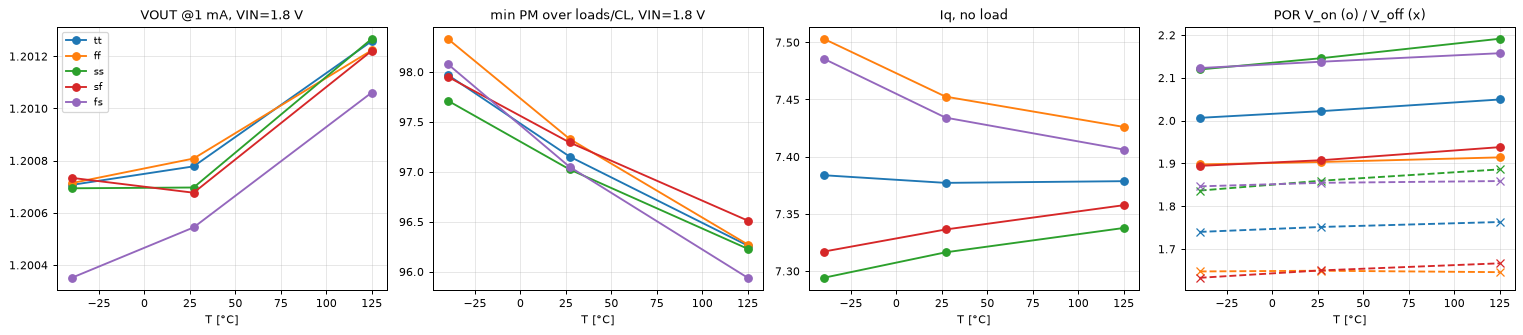

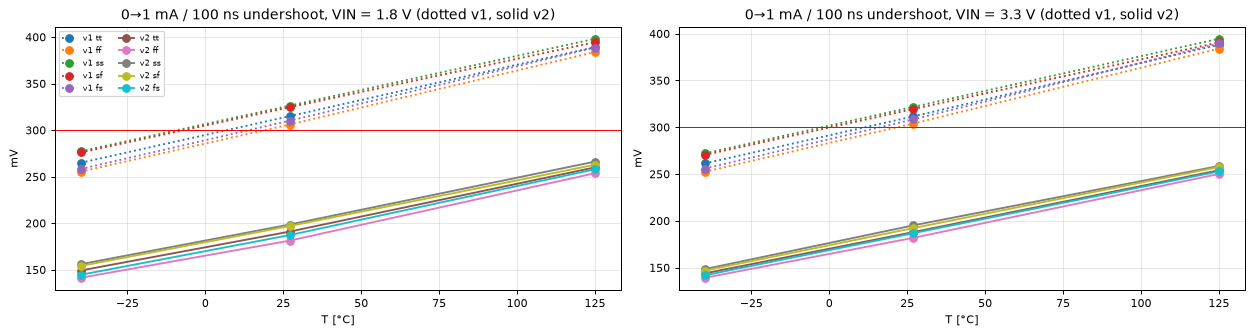

         T  vin  vout_0mA  vout_1mA  iq_uA  pm_0uA_100p  pm_0uA_10p  pm_10uA_100p  pm_1000uA_100p  pm_1000uA_10p  psrr1k  psrr_band
min  -40.0  1.8     1.200     1.200  7.294       95.825     102.518       102.322         128.580        128.905  34.577      8.422
max  125.0  3.3     1.206     1.201  7.537       98.576     105.622       106.990         136.182        137.199  56.534      9.360
         voff                  von              
T        -40     27     125   -40     27     125
corner                                          
ff      1.648  1.649  1.646  1.898  1.903  1.914
fs      1.846  1.855  1.859  2.123  2.138  2.157
sf      1.633  1.650  1.666  1.894  1.907  1.938
ss      1.836  1.860  1.886  2.119  2.146  2.191
tt      1.740  1.751  1.763  2.006  2.022  2.049
        under_100ns  over_100ns  under_1us  over_1us
design                                              
v1            398.1       348.1      281.9     295.4
v2            266.1       170.4      133.3      86.2


In [18]:
def pvt_job(a):
    c, T, v = a
    o0 = op_point(P0, v, 0, c, T); o1 = op_point(P0, v, 1e-3, c, T)
    pms = {f"pm_{il*1e6:g}uA_{cl*1e12:g}p": loop(P0, v, il, cl, c, T)["pm"]
           for il, cl in ((0, 100e-12), (0, 10e-12), (10e-6, 100e-12), (1e-3, 100e-12), (1e-3, 10e-12))}
    ps = psrr(P0, v, 0, 100e-12, c, T); ps1 = psrr(P0, v, 1e-3, 100e-12, c, T)
    band = lambda d: d.psrr[(d.f >= 1e5) & (d.f <= 1e6)].min()
    return dict(corner=c, T=T, vin=v, vout_0mA=o0["vout"], vout_1mA=o1["vout"], iq_uA=o0["iq"]*1e6, **pms,
                psrr1k=min(np.interp(1e3, ps.f, ps.psrr), np.interp(1e3, ps1.f, ps1.psrr)), psrr_band=min(band(ps), band(ps1)))
CORNERS, TEMPS = ["tt", "ff", "ss", "sf", "fs"], [-40, 27, 125]
PVT = pd.DataFrame(pmap(pvt_job, list(itertools.product(CORNERS, TEMPS, [1.8, 2.5, 3.3]))))
PMCOLS = [c for c in PVT.columns if c.startswith("pm_")]
def por_job(a):
    c, T = a; _, r = por_sweep(P0, c, T, tramp=0.4e-3); return dict(corner=c, T=T, von=r["von"], voff=r["voff"])
PORPVT = pd.DataFrame(pmap(por_job, list(itertools.product(CORNERS, TEMPS))))
def tload_job(a, P=None):
    c, T, v, nm = a; P = P0 if nm == "v2" else P_V1
    _, r = tran_load(P, v, 0, 1e-3, 1e-6, corner=c, temp=T)
    _, q = tran_load(P, v, 0, 1e-3, 100e-9, corner=c, temp=T)
    return dict(design=nm, corner=c, T=T, vin=v, under_1us=(r["vpre"]-r["vmin"])*1e3, over_1us=(r["vmax"]-r["vpre"])*1e3,
                under_100ns=(q["vpre"]-q["vmin"])*1e3, over_100ns=(q["vmax"]-q["vpre"])*1e3)
TLALL = pd.DataFrame(pmap(tload_job, list(itertools.product(CORNERS, TEMPS, [1.8, 3.3], ["v1", "v2"]))))
TLPVT, TLPVT_V1 = TLALL[TLALL.design == "v2"], TLALL[TLALL.design == "v1"]
def v1_job(a):   # v1 phase margin and Iq over the same PVT grid (for the before/after table)
    c, T, v = a
    ps = [psrr(P_V1, v, il, 100e-12, c, T) for il in (0, 1e-3)]
    return dict(corner=c, T=T, vin=v, iq_uA=op_point(P_V1, v, 0, c, T)["iq"]*1e6,
                pm=min(loop(P_V1, v, il, cl, c, T)["pm"] for il, cl in ((0, 100e-12), (0, 10e-12), (1e-3, 100e-12))),
                psrr1k=min(np.interp(1e3, d.f, d.psrr) for d in ps))
PVT_V1 = pd.DataFrame(pmap(v1_job, list(itertools.product(CORNERS, TEMPS, [1.8, 3.3]))))
def ss_job(a):   # small-step damping over PVT (covers the inner current-buffer loop)
    c, T, il, cl = a; _, s = small_step(P0, il, None, cl, 1.8, c, T); return dict(corner=c, T=T, IL_uA=il*1e6, CL_pF=cl*1e12, **s)
SSPVT = pd.DataFrame(pmap(ss_job, list(itertools.product(CORNERS, TEMPS, [0, 10e-6, 100e-6, 1e-3], [10e-12, 100e-12]))))
w = SSPVT.loc[SSPVT.overshoot_pct.idxmax()]
print(f"small-step overshoot over PVT (VIN 1.8 V): max {w.overshoot_pct:.1f} % at {w.corner}, {w['T']} °C, IL {w.IL_uA:g} µA, CL {w.CL_pF:g} pF")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for c in CORNERS:
    g = PVT[(PVT.corner == c) & (PVT.vin == 1.8)]
    ax[0].plot(g["T"], g.vout_1mA, "o-", label=c); ax[1].plot(g["T"], g[PMCOLS].min(axis=1), "o-", label=c)
    ax[2].plot(g["T"], g.iq_uA, "o-", label=c)
    g = PORPVT[PORPVT.corner == c]; ax[3].plot(g["T"], g.von, "o-", label=f"{c} V_on"); ax[3].plot(g["T"], g.voff, "x--", color=ax[3].lines[-1].get_color())
for a, t in zip(ax, ["VOUT @1 mA, VIN=1.8 V", "min PM over loads/CL, VIN=1.8 V", "Iq, no load", "POR V_on (o) / V_off (x)"]):
    a.set_title(t, fontsize=10); a.set_xlabel("T [°C]"); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
# before/after: 100 ns load-step undershoot over PVT
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, v in zip(ax, (1.8, 3.3)):
    for nm, D, ls in (("v1", TLPVT_V1, ":"), ("v2", TLPVT, "-")):
        for c in CORNERS:
            g = D[(D.corner == c) & (D.vin == v)]
            a.plot(g["T"], g.under_100ns, "o" + ls, label=f"{nm} {c}")
    a.axhline(300, color="r", lw=.8); a.set(title=f"0→1 mA / 100 ns undershoot, VIN = {v} V (dotted v1, solid v2)", xlabel="T [°C]", ylabel="mV"); a.grid(alpha=.3)
ax[0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()
print(PVT.describe().loc[["min", "max"]].round(3).to_string())
print(PORPVT.pivot_table(index="corner", columns="T", values=["von", "voff"]).round(3).to_string())
print(TLALL.groupby("design")[["under_100ns", "over_100ns", "under_1us", "over_1us"]].max().round(1).to_string())
w = TLPVT.loc[TLPVT.under_100ns.idxmax()]; print(f"v2 worst 100 ns undershoot: {w.under_100ns:.0f} mV at {w.corner}, {w['T']} °C, VIN {w.vin} V")

### 11.2 Monte Carlo (local mismatch, tt, 27 °C, 200 samples)

Mismatch comes from the SKY130 statistical model (`mc_mm_switch = 1`, Pelgrom-scaled with 1/√(W·L·mult)). Poly-resistor mismatch is not part of the
public ngspice models (see Limitations), so the POR spread here only covers the transistors.

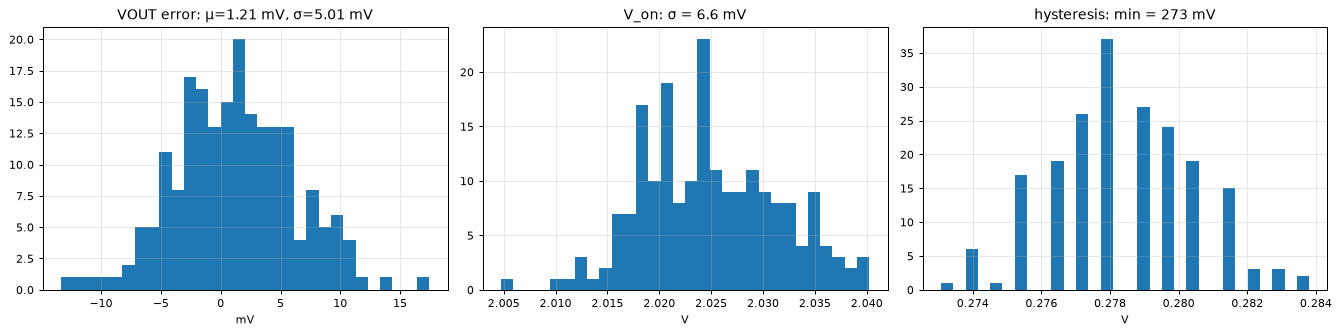

           seed      vout        iq       von      voff
count  200.0000  200.0000  200.0000  200.0000  200.0000
mean   100.5000    1.2012    7.3805    2.0249    1.7465
std     57.8792    0.0050    0.2331    0.0066    0.0053
min      1.0000    1.1867    6.8111    2.0048    1.7292
25%     50.7500    1.1976    7.2005    2.0202    1.7424
50%    100.5000    1.2011    7.3580    2.0246    1.7457
75%    150.2500    1.2043    7.5575    2.0297    1.7506
max    200.0000    1.2174    8.0293    2.0402    1.7597


In [19]:
def mc_job(s):
    o = op_point(P0, 2.5, 0, "tt", 27, True, s)
    _, r = por_sweep(P0, "tt", 27, True, s, tramp=0.2e-3)
    return dict(seed=s, vout=o["vout"], iq=o["iq"]*1e6, von=r["von"], voff=r["voff"])
MC = pd.DataFrame(pmap(mc_job, range(1, 201)))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist((MC.vout - 1.2)*1e3, 30); ax[0].set(title=f"VOUT error: μ={((MC.vout-1.2)*1e3).mean():.2f} mV, σ={MC.vout.std()*1e3:.2f} mV", xlabel="mV")
ax[1].hist(MC.von, 30); ax[1].set(title=f"V_on: σ = {MC.von.std()*1e3:.1f} mV", xlabel="V")
ax[2].hist(MC.von - MC.voff, 30); ax[2].set(title=f"hysteresis: min = {(MC.von-MC.voff).min()*1e3:.0f} mV", xlabel="V")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(MC.describe().round(4).to_string())

<a name="stress"></a>
## 12. Device voltage-stress check

This check was added because it is easy to get wrong: a 1.8 V device placed on a 3.3 V node passes simulation without any
warning but would break down in silicon. The cell below runs the operating point at the worst supply (VIN = 3.6 V, i.e. clamp
overshoot) in both POR states and both load conditions. It then computes |VGS|, |VDS|, |VGD|, |VGB| of **every** transistor from the
generated netlist and compares them with the limits of the device actually used and with the limits of a 1.8 V device.

In [20]:
STRESS = stress_check(P0)
print(STRESS.sort_values("worst_V", ascending=False).round(2).to_string(index=False))
print(f"\nmax terminal voltage on any FET: {STRESS.worst_V.max():.2f} V  (g5v0d10v5 rating: |VGS| <= 5.5 V, |VDS| <= 10.5 V)")
print(f"devices that would be OVER-STRESSED if they were 1.8 V (01v8) devices: {(STRESS.worst_V > 1.98).sum()} of {len(STRESS)}")

block device          model  worst_V                 at  VGS  VDS
  por   MI2N nfet_g5v0d10v5     3.60 VIN=3.6 V, IL=0 mA 3.60 0.00
  por   MI1N nfet_g5v0d10v5     3.60 VIN=3.6 V, IL=0 mA 0.19 3.60
  por   MI2P pfet_g5v0d10v5     3.60 VIN=3.6 V, IL=0 mA 0.00 3.60
  por   MI1P pfet_g5v0d10v5     3.41 VIN=3.6 V, IL=0 mA 3.41 0.00
  ldo    MPS pfet_g5v0d10v5     2.75 VIN=3.6 V, IL=0 mA 0.77 2.75
  ldo    MN2 nfet_g5v0d10v5     2.53 VIN=3.6 V, IL=0 mA 0.90 2.53
  por     MD nfet_g5v0d10v5     2.53 VIN=3.6 V, IL=0 mA 2.53 0.19
  ldo    MNX nfet_g5v0d10v5     2.50 VIN=3.6 V, IL=0 mA 0.87 2.50
  ldo    MPP pfet_g5v0d10v5     2.40 VIN=3.6 V, IL=1 mA 1.11 2.40
  ldo    MN1 nfet_g5v0d10v5     2.23 VIN=3.6 V, IL=0 mA 0.90 2.23
  ldo   MNB3 nfet_g5v0d10v5     2.20 VIN=3.6 V, IL=0 mA 0.87 2.20
  por   MI3N nfet_g5v0d10v5     1.90 VIN=1.9 V, IL=0 mA 1.90 0.00
  por     MH nfet_g5v0d10v5     1.90 VIN=1.9 V, IL=0 mA 1.90 0.00
  por   MI3P pfet_g5v0d10v5     1.90 VIN=1.9 V, IL=0 mA 0.70 1.20
  ldo    M

<a name="results"></a>
## 13. Specifications vs. results

In [21]:
def row(name, target, value, ok, before="", info=False):
    return dict(Parameter=name, Target=target, **{"v1 (before)": before}, **{"v2 result": value},
                Status=("INFO " if info else "") + ("PASS" if ok else "FAIL"))
vout_all = pd.concat([PVT.vout_0mA, PVT.vout_1mA])
mc3 = 3*MC.vout.std()
err = max(abs(vout_all.max()-1.2) + mc3, abs(vout_all.min()-1.2) + mc3) / 1.2 * 100
pm_min = PVT[PMCOLS].min().min()
hyst = (PORPVT.von - PORPVT.voff)
ldu = TL[100e-9]; ldu_v1 = TL_V1[100e-9]
def pm_from_overshoot(os_pct):        # 2nd-order closed loop: overshoot -> damping -> phase margin
    if not os_pct > 0: return 90.0
    L = np.log(os_pct/100); z = -L/np.sqrt(np.pi**2 + L**2)
    return np.degrees(np.arctan(2*z/np.sqrt(np.sqrt(1 + 4*z**4) - 2*z**2)))
OS_MAX = SSPVT.overshoot_pct.max(); PM_EQ = pm_from_overshoot(OS_MAX)
pk = lambda r: (f"-{(r['vpre']-r['vmin'])*1e3:.0f} / +{(r['vmax']-r['vpre'])*1e3:.0f} mV", max(r['vpre']-r['vmin'], r['vmax']-r['vpre']))
ln = lambda r: (f"+{(r['vmax']-r['vpre'])*1e3:.0f} / -{(r['vpre']-r['vmin'])*1e3:.0f} mV", max(r['vmax']-r['vpre'], r['vpre']-r['vmin']))
w100 = max(TLPVT.under_100ns.max(), TLPVT.over_100ns.max()); w100_v1 = max(TLPVT_V1.under_100ns.max(), TLPVT_V1.over_100ns.max())
w1u = max(TLPVT.under_1us.max(), TLPVT.over_1us.max()); w1u_v1 = max(TLPVT_V1.under_1us.max(), TLPVT_V1.over_1us.max())
RES = pd.DataFrame([
 row("VIN range (regulating, 1 mA)", "1.8 – 3.3 V", f"VOUT@1.8 V,1 mA: {PVT[PVT.vin==1.8].vout_1mA.min():.4f}–{PVT[PVT.vin==1.8].vout_1mA.max():.4f} V (PVT)", PVT[PVT.vin==1.8].vout_1mA.min() > 1.17),
 row("VOUT accuracy (PVT + 3σ MC)", "± 3 %", f"± {err:.2f} %  (ideal VREF)", err <= 3, "± 1.33 % (earlier full run)"),
 row("Quiescent current, LDO (PVT max)", "≤ 10 µA", f"{PVT.iq_uA.max():.2f} µA", PVT.iq_uA.max() <= 10, f"{PVT_V1.iq_uA.max():.2f} µA"),
 row("POR supply current", "≤ 2 µA", f"{IPOR[2.0]*1e6:.2f} µA @2 V, {IPOR[3.3]*1e6:.2f} µA @3.3 V", max(IPOR.values()) <= 2e-6),
 row("Dropout @1 mA (tt 27 °C)", "≤ 400 mV", f"{VDROP*1e3:.0f} mV", VDROP <= 0.4, f"{VDROP_V1*1e3:.0f} mV"),
 row("Line regulation", "≤ 5 mV/V", f"{LINEREG*1e3:.2f} mV/V", LINEREG <= 5e-3, f"{LINEREG_V1*1e3:.2f} mV/V"),
 row("Load regulation", "≤ 5 mV/mA", f"{max(LOADREG.values())*1e3:.2f} mV/mA", max(LOADREG.values()) <= 5e-3, f"{LOADREG_V1*1e3:.2f} mV/mA"),
 row("Phase margin (PVT; 0/10 µA/1 mA; 10/100 pF)", "≥ 45°", f"loop-gain PM {pm_min:.0f}° min; small-step overshoot ≤ {OS_MAX:.0f} % (≈ 2nd-order PM {PM_EQ:.0f}°)", min(pm_min, PM_EQ) >= 45, f"{PVT_V1.pm.min():.1f}° min"),
 row("PSRR @1 kHz (PVT, 0 and 1 mA)", "≥ 30 dB", f"{PVT.psrr1k.min():.1f} dB min", PVT.psrr1k.min() >= 30, f"{PVT_V1.psrr1k.min():.1f} dB min"),
 row("PSRR, worst in 100 kHz – 1 MHz (tt)", "improve (no spec)", f"{PSRRBAND:.1f} dB (PVT min {PVT.psrr_band.min():.1f} dB); @847 kHz {PSRR847:.1f} dB", PSRRBAND > PSRRBAND_V1 + 6,
     f"{PSRRBAND_V1:.1f} dB; @847 kHz {PSRR847_V1:.1f} dB", info=True),
 row("Load step 0↔1 mA, 100 ns (tt, 2.5 V)", "≤ 300 mV", pk(ldu)[0], pk(ldu)[1] <= 0.3, pk(ldu_v1)[0]),
 row("Load step 0↔1 mA, 100 ns (PVT, 1.8/3.3 V)", "≤ 300 mV", f"{w100:.0f} mV worst", w100 <= 300, f"{w100_v1:.0f} mV worst"),
 row("Load step 0↔1 mA, 1 µs (PVT, 1.8/3.3 V)", "≤ 300 mV", f"{w1u:.0f} mV worst", w1u <= 300, f"{w1u_v1:.0f} mV worst"),
 row("Line step 2↔3 V / 10 µs (tt)", "≤ 100 mV", ln(TLINE[10e-6])[0], ln(TLINE[10e-6])[1] <= 0.1, ln(TLINE_V1[10e-6])[0]),
 row("Line step 2↔3 V / 1 µs (tt, stress test)", "≤ 100 mV", ln(TLINE[1e-6])[0], ln(TLINE[1e-6])[1] <= 0.1, ln(TLINE_V1[1e-6])[0], info=True),
 row("Transient FoM (Hazucha, tt)", "lower is better", f"{FOM_T*1e12:.0f} ps", True, f"{FOM_T_V1*1e12:.0f} ps", info=True),
 row("Total MIM area of the LDO", "—", f"{mim_area(P0):.0f} µm²", True, f"{mim_area(P_V1):.0f} µm²", info=True),
 row("POR V_on (PVT)", "2.0 V ± 10 %", f"{PORPVT.von.min():.3f} – {PORPVT.von.max():.3f} V", PORPVT.von.min() >= 1.8 and PORPVT.von.max() <= 2.2),
 row("POR hysteresis (PVT, MC min)", "≥ 150 mV", f"{hyst.min()*1e3:.0f} mV (PVT), {(MC.von-MC.voff).min()*1e3:.0f} mV (MC)", min(hyst.min(), (MC.von-MC.voff).min()) >= 0.15),
 row("POR V_off (PVT)", "≥ 1.6 V", f"{PORPVT.voff.min():.3f} V min", PORPVT.voff.min() >= 1.6),
 row("VOUT settled before RST release", "within 2 %", f"{SYS['vout_at_release']:.3f} V", abs(SYS['vout_at_release']-1.2) <= 0.024),
 row("Device stress (all FETs thick-oxide)", "|V| ≤ 5.5 V", f"{STRESS.worst_V.max():.2f} V max", STRESS.worst_V.max() <= 5.5),
])
def color(v): return "color: gray" if v.startswith("INFO") else ("color: green; font-weight: bold" if v == "PASS" else "color: red; font-weight: bold")
try:
    display(RES.style.map(color, subset=["Status"]))
except AttributeError:
    display(RES.style.applymap(color, subset=["Status"]))
print(RES.to_string(index=False))
print(f"\n{(RES.Status=='PASS').sum()} PASS, {(RES.Status=='FAIL').sum()} FAIL (+{RES.Status.str.startswith('INFO').sum()} informational)")

,Parameter,Target,v1 (before),v2 result,Status
0,"VIN range (regulating, 1 mA)",1.8 – 3.3 V,,"VOUT@1.8 V,1 mA: 1.2004–1.2013 V (PVT)",PASS
1,VOUT accuracy (PVT + 3σ MC),± 3 %,± 1.33 % (earlier full run),± 1.77 % (ideal VREF),PASS
2,"Quiescent current, LDO (PVT max)",≤ 10 µA,8.72 µA,7.54 µA,PASS
3,POR supply current,≤ 2 µA,,"0.85 µA @2 V, 1.54 µA @3.3 V",PASS
4,Dropout @1 mA (tt 27 °C),≤ 400 mV,339 mV,378 mV,PASS
5,Line regulation,≤ 5 mV/V,0.19 mV/V,1.60 mV/V,PASS
6,Load regulation,≤ 5 mV/mA,0.36 mV/mA,2.43 mV/mA,PASS
7,Phase margin (PVT; 0/10 µA/1 mA; 10/100 pF),≥ 45°,63.3° min,loop-gain PM 96° min; small-step overshoot ≤ 17 % (≈ 2nd-order PM 51°),PASS
8,"PSRR @1 kHz (PVT, 0 and 1 mA)",≥ 30 dB,22.5 dB min,34.6 dB min,PASS
9,"PSRR, worst in 100 kHz – 1 MHz (tt)",improve (no spec),-0.4 dB; @847 kHz -0.1 dB,8.7 dB (PVT min 8.4 dB); @847 kHz 11.4 dB,INFO PASS


                                  Parameter            Target                 v1 (before)                                                              v2 result    Status
               VIN range (regulating, 1 mA)       1.8 – 3.3 V                                                             VOUT@1.8 V,1 mA: 1.2004–1.2013 V (PVT)      PASS
                VOUT accuracy (PVT + 3σ MC)             ± 3 % ± 1.33 % (earlier full run)                                                 ± 1.77 %  (ideal VREF)      PASS
           Quiescent current, LDO (PVT max)           ≤ 10 µA                     8.72 µA                                                                7.54 µA      PASS
                         POR supply current            ≤ 2 µA                                                                       0.85 µA @2 V, 1.54 µA @3.3 V      PASS
                   Dropout @1 mA (tt 27 °C)          ≤ 400 mV                      339 mV                                                        

**What v2 costs (regressions versus v1, all still inside the specs):**
* Damping margin: equivalent PM from the small-step overshoot ≈ 51° in the worst PVT corner (v1: ≥ 63° loop-gain PM).
* DC accuracy terms: the buffer stack has finite output resistance at `vg`, so the DC loop gain is ≈ 5 dB lower. Load regulation
  goes 0.36 → 2.4 mV/mA, line regulation 0.19 → 1.6 mV/V, and the Monte Carlo VOUT spread grows, because mismatch between
  the PMOS and NMOS buffer currents appears as an input offset ΔIx/gm1. Doubling the tail current (2× gm1) was the countermeasure.
* Dropout at 1 mA: 339 → 378 mV (wider OTA mirror and buffer headroom at low VIN).
* Low-frequency PSRR (below ≈ 1 kHz) is ≈ 20 dB lower at no load (≈ 82 → ≈ 58 dB at 1 Hz), but the 1 kHz spec is met over PVT and
  is actually *better* than v1 in the worst case (v1 failed it at sf, 1.8 V, 1 mA with ≈ 22 dB when tested with load).
* MIM area: 4,900 → 8,460 µm² (≈ +0.004 mm²).
* In exchange: the 100 ns load step passes over all PVT corners (398 → 266 mV worst), the 1 µs load step and the line steps improve
  2–7×, the transient FoM halves, mid-band PSRR improves from ≈ 0 to ≈ 9 dB, and Iq *drops* from 8.7 to 7.5 µA.

**Context: published capacitor-less LDOs (same figure of merit).**
The values for the four published designs are copied from Table 1 of X. Ming, Z.-K. Zhou, B. Zhang, *"A Low-Power Ultra-Fast
Capacitor-Less LDO With Advanced Dynamic Push-Pull Techniques"*, VLSI-SoC 2011 (IFIP), which compares them with one figure of merit:
FOM = T_settle · I_Q / I_load,max, with T_settle = C_load · ΔV_OUT / I_load,max (lower is better).
The last column uses the same formula with this notebook's saved results at C_load = 100 pF and I_load,max = 1 mA: tt (ΔV_OUT = 188 mV, the
"Transient FoM (Hazucha)" row of Section 13, 139 ps) and the worst of 45 PVT corners (ΔV_OUT = 266 mV, I_Q = 7.54 µA).

| | Hazucha 2005 [JSSC] | Man 2007 [TCAS-II] | Or & Leung 2010 [JSSC] | Milliken 2007 [TCAS-I] | **This work** |
|---|---|---|---|---|---|
| Technology | 90 nm | 0.18 µm | 0.35 µm | 0.35 µm | 130 nm (SKY130, thick-oxide devices) |
| V_IN | 1.2 V | 1–1.8 V | 0.95–1.4 V | 3–4.2 V | 1.8–3.3 V |
| Dropout | 300 mV | 100 mV | 200 mV | 200 mV | 378 mV (tt, 1 mA) |
| I_Q | 6000 µA | 1.2 µA | 43 µA | 65 µA | 7.54 µA (PVT max) |
| I_load,max | 100 mA | 50 mA | 100 mA | 50 mA | 1 mA |
| Load regulation | N/A | 0.148 mV/mA | ≈ 0.4 mV/mA | ≈ 0.56 mV/mA | 2.43 mV/mA |
| Line regulation | N/A | 3.625 mV/V | N/A | ≈ 23 mV/V | 1.60 mV/V |
| T_settle | 0.54 ns | ≈ 2.8 µs | ≈ 3 µs | ≈ 15 µs | 18.8 ns (tt) / 26.6 ns (PVT worst) |
| **FOM** | **0.032 ns** | **0.067 ns** | **1.29 ns** | **19.5 ns** | **0.14 ns (tt) / 0.20 ns (PVT worst)** |
| Data | measured | measured | measured | measured | **simulated, schematic level** |

**How to read this table.** This work is a 1 mA design for a harvested tag, while the others serve 50–100 mA loads, so it trades
regulation accuracy (2.43 mV/mA) and dropout for a small quiescent current. On this FOM it sits between the two current-efficient
designs (0.032 and 0.067 ns) and the two slower ones (1.29 and 19.5 ns). The comparison is only indicative: the published numbers are
silicon measurements reported through a secondary table, and the comparison uses this work's schematic-level results (layout and post-layout results are in Section 16).


<a name="limits"></a>
## 14. Limitations and future work (honest list)

* **Ideal reference and bias.** VREF (1.2 V) and Iref (250 nA) are ideal sources with a simple start-up model.
  A real tag needs a nano-power reference. Its start-up, noise and PSRR add to the results above, so VOUT accuracy here
  **excludes** reference error. Section 16 adds a transistor-level bandgap and re-verifies the whole block with it.
* **Load transient (v2).** The 100 ns step now meets 300 mV in every PVT corner, but the margin at ss/sf, 125 °C, 1.8 V is only a few
  tens of mV. The droop still grows with temperature (the pass-gate swing ∝ U_T). The transient enhancement relies on MIM capacitors
  and on node `sx`/`tx` parasitics that a layout would increase, so post-layout extraction is needed before trusting the margin.
* **PSRR in 100 kHz – 1 MHz is improved (≈ 0 dB → ≈ 9 dB) but still weak**, and this band includes the 847 kHz NFC subcarrier.
  More feed-forward costs droop (Section 9.4). An RC pre-filter on VIN, or a ripple-replica / feed-forward cancellation path with
  its own gain, would be the next step.
* **The current buffers are biased from VREF (MNX gate) and from an Rsh level shift (MPX gate).** Their headroom was checked over
  PVT and VIN = 1.8–3.3 V, but not over a real reference's start-up. At very low VIN the buffers are off, and the LDO output is held near 0 V
  (the POR keeps the core in reset there).
* **Slew-rate-limited line response** is much better in v2 (1 V/µs: ≈ 0.1 V overshoot instead of 0.7 V), but it is not eliminated.
* **Resistor mismatch and process spread are not modelled** in the POR Monte Carlo (`mc_pr_switch = 0`). The divider ratio is
  ratiometric, but Rpu's absolute value shifts the detector current, so expect a somewhat wider V_on spread in silicon.
* **Sections 1–14 are schematic-level.** Layout, DRC/LVS, C extraction and post-layout PVT re-simulation are in Section 16 (v3).
  Still missing: RC extraction, ESD, and any antenna/rectifier model beyond a current source. The xschem schematic is a
  label-connected netlist entry (no drawn wiring).
* Corner coverage: MOS corners tt/ff/ss/sf/fs. Resistor/capacitor corners were not swept separately.
* **Noise** (Section 9.6) is reported at tt only, without a spec, and excludes the reference. The comparison with published
  cap-less LDOs (Section 13) is indicative only: those designs use different processes, load ranges and I_Q, their numbers are
  silicon measurements, and the numbers here are schematic-level simulations.

<a name="v3"></a>
## 16. v3: transistor-level reference, physical layout and post-layout verification

The `layout/` folder next to this notebook adds three things the schematic-level notebook did not have:

1. **A transistor-level nano-power bandgap reference.** It replaces the ideal VREF (1.2 V) and Iref (250 nA) sources.
2. **A complete scripted layout of LDO + POR + bandgap**, with DRC and LVS sign-off.
3. **Parasitic extraction and post-layout re-simulation** of the whole block over 45 PVT points: load step, small-step damping, Iq, POR thresholds and PSRR.

Everything is reproduced by `layout/scripts/run_all.sh`: device cells, placement and routing, DRC/LVS, C extraction, then all simulations.

### Bandgap (`layout/scripts/lib.py`: `bgr_subckt`, `BGR0`)

The bandgap has no op-amp. Its parts:

- a self-biased PTAT core: native 5 V NMOS pair (`nfet_05v0_nvt`, W/L = 1/25 × 6) and vertical PNPs at 1:8
- a self-cascoded PMOS mirror
- a level-shifted PMOS diode, to keep headroom at low VIN in the cold
- start-up sensed through a PNP (release NMOS gate at VREF, source on a VBE)
- VREF = I·R2 + VBE, with a 5-bit trim on R2 (LSB 25 kΩ, about 2 mV)
- a supply-ripple filter **outside the bandgap loop**: 2 MΩ into 5 pF of MIM, between the core output and the LDO's reference input

The filter sits behind a resistor on purpose. With the MIM directly on the core output, the start-up release (which senses VREF) was delayed. The kick then overshot VREF, and at −40 °C the core collapsed into its zero-current state in three post-layout corners. Behind 2 MΩ the core and its start-up see no extra load. The LDO's reference input is a MOS gate, so the resistor adds no DC error.

All results below come from power-up transients:

| | Result |
|---|---|
| VREF (tt, 27 °C, 2.5 V) | 1.1996 V; 1.1960 / 1.1996 / 1.2035 V at −40 / 27 / 125 °C (7.5 mV) |
| PVT (5 corners × 3 temperatures × 3 supplies) | 42 / 45 points within ±1 %. Exceptions: ss / 125 °C / 3.3 V (+1.0 %), fs / 125 °C / 3.3 V (+3.3 %), sf / −40 °C / 1.8 V (−5 %, headroom; recovers at 1.85 V) |
| Monte Carlo, untrimmed (200 chips) | σ = 0.86 % (mainly PMOS-mirror mismatch) |
| Monte Carlo, trimmed once at 27 °C / 2.5 V (100 chips) | −0.61 % … +0.96 % over −40/27/125 °C and 1.8/2.5/3.3 V |
| Supply current (tt, 2.5 V) | 0.44 / 0.63 / 0.96 µA at −40 / 27 / 125 °C |
| Supply rejection at the filtered output (tt) | 34.5 dB at 1 kHz; 21.8–38.6 dB from 10 kHz to 847 kHz (it was −0.4 dB at 100 kHz without the filter) |
| Start-up on a slow ramp (0 → 3.3 V in 10 ms) | VREF is up by VIN = 1.27–1.61 V at −40 / 27 °C and 1.59–2.18 V at 125 °C. The exception is ss / 125 °C at 2.49 V. It releases cleanly at every corner. |

### Layout (`layout/ldo_top.gds`)

![LDO + POR + bandgap layout (KLayout render)](layout/ldo_top.png)

- **Fully scripted.** `layout/scripts/layout.py` reads the same subcircuits the simulations use. It places Magic-generated PDK devices (96 cells) and routes them:
  - metal3 risers from every terminal
  - one metal4 track per net in channels between the rows
  - metal3 trunks
  - 3 µm-wide supply and output nets
- **Size:** 390 × 524 µm.
  - Wide mirror and pass devices are split into ≤ 20 µm fingers, so rows stay short and the risers that couple VIN into VOUT stay short.
  - VIN–VOUT coupling: 0.49 pF, down from 1.5 pF in the first placement.
- **Trim:** bits are hard-wired to code 16 (a metal option; fuses in a product).

**Verification** (`layout/scripts/verify.sh`):

| Check | Result |
|---|---|
| KLayout, official `sky130A_mr.drc` deck (FEOL + BEOL + off-grid) | **0 violations** |
| Magic DRC on the flattened final GDS | **0 errors** |
| Netgen LVS (`layout/reports/lvs_report.txt`) | **Circuits match uniquely**, 77 devices / 46 nets, no property errors |

Notes:
- The PDK resistor generator draws URPM only 0.75 µm wide around a 0.35 µm poly resistor (rule urpm.1a needs 1.27 µm). Mask hints widen it to ≥ 1.27 µm, so the final GDS is clean.
- Magic's hierarchical check on the `.mag` view still reports RPM that it regenerates at cell interactions. That RPM is not in the GDS.

### Post-layout simulation (`layout/scripts/postlayout.py`, `layout/scripts/por_check.py`)

**Extraction.**
- Magic C extraction with coupling capacitance: 1,992 parasitic capacitors (`layout/reports/ldo_top_pexC.spice`).
- Every run is a power-up transient of the whole block (VIN ramps from 0 V in 1 ms). The bandgap start-up and the POR are therefore exercised as on a harvested tag.

**PVT: 5 corners × −40 / 27 / 125 °C × VIN 1.8 / 2.5 / 3.3 V = 45 points** (`layout/reports/postlayout_pvt_pex.csv`):

| | Spec | Post-layout result |
|---|---|---|
| 0 → 1 mA load step, 100 ns edge: undershoot | ≤ 300 mV | **≤ 279 mV** (worst at 125 °C; 209 mV at −40 °C, 240 mV at 27 °C) |
| 1 → 0 mA: overshoot | | ≤ 180 mV |
| Small-step (10 µA) recovery overshoot | | ≤ 17 %, except fs / −40 °C / ≥ 2.5 V: 24–26 % (VREF still settling, see below) |
| Iq, LDO + bandgap + POR (4 ms after power-up) | | 7.2 µA at tt / 27 °C; worst 12.8 µA (sf / −40 °C / 2.5 V); ≤ 11.5 µA at 125 °C |
| VOUT 4 ms after power-up, ±3 % | 1.164–1.236 V | 1.186–1.234 V at 43 / 45 points. **FAIL at fs / −40 °C / ≥ 2.5 V: 1.244 V (+3.7 %)**; it is 1.205 V at 8 ms |
| POR release V_on / hysteresis (15 corner × temperature points, `layout/reports/postlayout_por_pex.csv`) | 2.0 V ± 10 % / ≥ 150 mV | **1.894–2.192 V / ≥ 244 mV** |

**Spec status with the real bandgap, after layout.** The notebook's "18 PASS, 0 FAIL" (Section 13) is the schematic-level result with the ideal reference. After layout, with the bandgap:
- **Load step, POR, stability: PASS.**
- **PSRR at 1 kHz: FAIL**, 24.8 dB against ≥ 30 dB.
- **VOUT ±3 % at 4 ms: FAIL** at fs / −40 °C / ≥ 2.5 V (+3.7 %; it passes by 8 ms).
- **Quiescent current:** the ≤ 10 µA spec was for the LDO alone. The whole block (LDO + bandgap + POR) draws 7.2 µA at tt and up to 12.8 µA in the cold.
- **Usable VIN:** the POR keeps the core in reset below its release threshold (1.89–2.19 V over PVT), so RST_N stays low at VIN = 1.8 V by design.

**Post-layout PSRR at 1 kHz fails the notebook's 30 dB spec: 24.8 dB at tt** (34.9 dB before layout). The cause is not found; see the open points.

**Before vs after layout** (tt, 27 °C, 2.5 V; the same netlist without parasitics vs with them):

| | Pre-layout | Post-layout |
|---|---|---|
| Load-step undershoot / overshoot | 201 / 133 mV | 231 / 143 mV |
| Iq | 7.27 µA | 7.24 µA |
| PSRR at 1 kHz | 34.9 dB | 24.8 dB |
| PSRR at 100 kHz | 18.6 dB | 21.3 dB |
| PSRR at 847 kHz (NFC subcarrier) | 18.0 dB | 19.1 dB |
| VOUT | 1.2014 V | 1.1929 V |

Notes on the table:
- PSRR in the table is the ripple fitted at the test frequency, so slow drift is not counted.
- With the ideal reference, the notebook's PSRR was −0.4 dB at 100 kHz (v1) and 8.7 dB (v2).
- **VOUT −8.5 mV:** the extracted bandgap gives 1.191 V instead of 1.199 V (meandered high-resistance poly vs the schematic value). This is about 4 trim LSBs, well inside the trim range.

### Open points (measured, not hidden)

- **Start-up settling at fs / −40 °C, VIN ≥ 2.5 V.**
  - The start-up kick overshoots VREF to 1.67 V. It relaxes to 1.243 V at 4 ms, 1.205 V at 8 ms and 1.193 V at 16 ms.
  - Measured at 4 ms, this corner reads VOUT = 1.243 V and a 25 % small-step overshoot (the drift contaminates the step).
  - Cause: the release NMOS (gate VREF, source on a VBE) is weak in the cold, and making it stronger brings back the 125 °C slow-ramp start failure. A release driven by a copy of the core current would remove the trade-off. I tried one, but it raised the cold start VIN to 1.8–2.2 V.
  - The POR does not wait for VREF to settle. A product should add a ≈ 10 ms delay or a VREF-good comparator.
- **ss / 125 °C, slow ramp:**
  - The stand-alone bandgap is up only at VIN = 2.49 V.
  - In the full-block POR test, RST_N releases at 2.19 V at that corner.
  - So VREF may not be fully settled when reset releases there. This is not verified, and the same POR delay would cover it.
- **PSRR at 1 kHz drops 10 dB after layout** (34.9 → 24.8 dB), below the 30 dB spec. The cause is not identified yet. At 1 kHz the extracted capacitances alone should not matter, so the next step is to find which device geometry change (extracted vs schematic) costs the gain.
- **Not done:**
  - RC extraction is not in the simulations. Resistance extraction runs, but `extresist` fails on 37 native-device nodes.
  - No ESD, no antenna model, no rectifier model beyond a current source.
  - Sections 1–14 still use the ideal reference. The bandgap and post-layout results come from the scripts in `layout/scripts/`.

<a name="refs"></a>
## 15. Reproducibility, tools & assistance, references

**Tool versions used to produce the saved outputs:** ngspice-41 (conda-forge build), SKY130A from open_pdks
`792ef67037d74c8c51811eab3ce23cf793491296` installed with ciel 3.2.0, Python 3.12, numpy / pandas / matplotlib (conda-forge),
schemdraw 0.23. Executed on Ubuntu 24.04 (WSL2) with `jupyter nbconvert --execute`.

In [22]:
import platform, matplotlib, numpy, pandas
print("python", platform.python_version(), "| numpy", numpy.__version__, "| pandas", pandas.__version__,
      "| matplotlib", matplotlib.__version__, "| schemdraw", schemdraw.__version__)
print(subprocess.run(["ngspice", "-v"], capture_output=True, text=True).stdout.splitlines()[1].strip())
print("simulation runs in this session:", len([f for f in os.listdir(SIMDIR) if f.endswith('.spice')]))

python 3.12.15 | numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | schemdraw 0.23
** ngspice-41 : Circuit level simulation program
simulation runs in this session: 1479


**Tools & assistance.** I made this notebook with the help of an AI assistant (Claude, by Anthropic, used through
Claude Code). The assistant helped write the notebook code, the scripts that generate the notebook, and most of the text.
I chose the application and the specifications, ran the simulations, checked their results, and reviewed the final
notebook. All results for this design come from the ngspice simulations that this notebook runs. The open-source tools are
the SKY130 PDK (open_pdks), ngspice-41, xschem and schemdraw. Prior work that the design relies on is listed in the
references below.

### References
1. P. Hazucha, T. Karnik, B. A. Bloechel, C. Parsons, D. Finan, S. Borkar, "Area-efficient linear regulator with ultra-fast load regulation," *IEEE JSSC*, vol. 40, no. 4, 2005. (transient FoM)
2. K. N. Leung, P. K. T. Mok, "A capacitor-free CMOS low-dropout regulator with damping-factor-control frequency compensation," *IEEE JSSC*, vol. 38, no. 10, 2003.
3. R. J. Milliken, J. Silva-Martínez, E. Sánchez-Sinencio, "Full on-chip CMOS low-dropout voltage regulator," *IEEE TCAS-I*, vol. 54, no. 9, 2007.
4. G. A. Rincón-Mora, P. E. Allen, "A low-voltage, low quiescent current, low drop-out regulator," *IEEE JSSC*, vol. 33, no. 1, 1998.
5. P. G. A. Jespers, B. Murmann, *Systematic Design of Analog CMOS Circuits Using Pre-Computed Lookup Tables*, Cambridge Univ. Press, 2017.
6. I. M. Filanovsky, A. Allam, "Mutual compensation of mobility and threshold voltage temperature effects with applications in CMOS circuits," *IEEE TCAS-I*, vol. 48, no. 7, 2001. (ZTC point)
7. R. D. Middlebrook, "Measurement of loop gain in feedback systems," *Int. J. Electronics*, vol. 38, no. 4, 1975.
8. SkyWater Technology / Google, SKY130 open-source PDK documentation, https://skywater-pdk.readthedocs.io ; open_pdks, https://github.com/RTimothyEdwards/open_pdks ; ciel, https://github.com/fossi-foundation/ciel
9. ngspice manual, https://ngspice.sourceforge.io/docs.html ; schemdraw, https://schemdraw.readthedocs.io
10. IEEE SSCS Code-a-Chip repository and FAQ, https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io (notebook structure, install pattern)
11. B. K. Ahuja, "An improved frequency compensation technique for CMOS operational amplifiers," *IEEE JSSC*, vol. 18, no. 6, 1983. (current-buffer Miller compensation used in v2)
12. P. Y. Or, K. N. Leung, "An output-capacitorless low-dropout regulator with direct voltage-spike detection," *IEEE JSSC*, vol. 45, no. 2, 2010. (capacitively coupled transient enhancement in cap-less LDOs)
13. M. El-Nozahi, A. Amer, J. Torres, K. Entesari, E. Sánchez-Sinencio, "High PSR low drop-out regulator with feed-forward ripple cancellation technique," *IEEE JSSC*, vol. 45, no. 3, 2010. (supply feed-forward idea)

*Licensed under the Apache License, Version 2.0 (see `LICENSE` in this folder).*